<a href="https://colab.research.google.com/github/meliilopez/Herramientas_De_Software_Para_Analisis_De_Datos/blob/main/03_Port_Log_Grupo_07_FINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trabajo Práctico Integrador

## Port Log - Sprint 3

## Integrantes del grupo 07:



* Esteban Álvarez
* María Emilia Bazán
* Melina López
* Jorge Claure Endara
* Gustavo Mauro Zapana


## Repositorio GITHUB



> https://github.com/estuchis21/Port_Log-Grupo_07.git







## Consideraciones Generales e Importantes

- Desarrollo base: Los puntos solicitados son la base del trabajo práctico. Es posible la ampliación sin restricciones del mismo.
- Para el traceo se deben agregar 1 [secrets](https://drlee.io/how-to-use-secrets-in-google-colab-for-api-key-protection-a-guide-for-openai-huggingface-and-c1ec9e1277e0) para la utilización de github.
  - GITHUB_TOKEN
- Organización del Notebook:
  - Agregar antes del ejercicio 01 una celda donde se importan todas librerías necesarias.
  - Utilizar un título para cada celda y escribir cada funcionalidad en una celda con título.
- La defensa es individual.
- Los grupos deben mantenerse a lo largo del trabajo integrador.
- La opción `DESACTIVAR_GIT_PUSH` solo será utilizada por los profesores.

## Versionado y Trabajo en Equipo


- Control de Versiones: Utilizar herramientas de versionado
- Colaboradores: Brindar acceso al repositorio a las siguientes cuentas:
  - lcd-had141@ugr.edu.ar
  - fpasinato@ugr.edu.ar
- La descripción del commit debe ser con el siguiente formato `"Día X: \<comentario del commit\>"`
- Changelog: Cada ejercicio/punto del trabajo práctico es considerado como un día distinto de trabajo. Debe quedar constancia en un archivo CHANGELOG.md de los cambios generados cada día. El changelog debe escribirse de tal forma que lo primero que se observe es el último cambio realizado, de esta forma apenas se abre el archivo se pueden leer los últimos cambios realizados. La forma de escritura debe ser un encabezado entre corchetes [Ejercicio X] y luego debajo los cambios realizado como bullets.
- El archivo README.md debe contener el sprint en el que nos encontramos y debe contener:
  - El objetivo.
  - La introducción y el contexto del sprint de trabajo.

## Criterios de evaluación

- Funcionalidad: el código debe ejecutar sin errores al dar "Ejecutar todo" (Ctrl+F9). Validar con Runtime -> Restart session and run all antes de entregar.
- Claridad: código organizado, nombres descriptivos, comentarios solo donde corresponde (funciones, clases, métodos). No se admite `git add .`.
- Estilo: [type hints](https://docs.python.org/3/library/typing.html), [pep8](https://peps.python.org/pep-0008/).

- Herramientas: librerías vistas en la cursada. Sin gdrive ni herramientas alternativas.

## Condiciones de Entrega
- Archivo `.ipynb`, ejecutado y con datos precargados, sobre copia de la plantilla original manteniendo la nomenclatura del nombre.
- Canal: aula virtual. Correo a lcd-had141@ugr.edu.ar solo si el plazo finalizó. No se aceptan enlaces.
- Los trabajos que no cumplan con los requisitos no serán tomados en cuenta como nota final. Solo serán corregidos y evaluados con nota para la devolución correspondiente. Se considera incumplimiento a:
  - Entregas fuera de término.
  - Trabajos que no se entreguen sobre la plantilla de trabajo estipulada.
  - Trabajos que no se ejecuten completos (que contengan errores intermedios al dar "Ejecutar todo").

---

## Extras

- [Manual Supabase](https://colab.research.google.com/drive/1bAL9yrkwByR3Qf6nviotKErYFcLAzcnL).
- [SQLAlchemy](https://colab.research.google.com/drive/1QBzLEKc6juktyqMYO6nz8QVMm1eMzvWY)
- Base de datos vectoriales chromadb [BaseDeDatosVectorialPPT](https://colab.research.google.com/drive/1nazuIlHGC_Od0Kbf5nPp6yEMk5dfJfQY) y [BaseDeDatosVectoriales](https://colab.research.google.com/drive/1z26X154sj9UAWhjpoUl9Ov2jnVxTm4iA)



## Objetivo

Aplicar conocimientos de bases de datos relacionales (SQLAlchemy), versionado de datos (DVC) y búsqueda por similitud visual (ChromaDB) para profesionalizar el sistema portuario.

## Introducción y Contexto del problema


### Sprint 3 — Desarrollar

El sistema ha crecido en volumen y complejidad. El equipo de desarrollo portuario necesita:

1. **Persistencia estructurada**: pasar de CSVs a una base de datos relacional con ORM.
2. **Auditoría de cambios**: poder rastrear qué versión del dataset se usó en cada análisis.
3. **Identificación visual de buques**: dado que la OCR no siempre funciona bien, el sistema debe poder identificar un buque por similitud visual de su imagen, sin depender del texto.

In [ ]:
#@title Instalación de paquetes
!pip install -q sqlalchemy chromadb open-clip-torch dvc[s3]

In [ ]:
#@title Importación de librerías
import base64
import json
import math
import os
import re
import subprocess
import sys
import zipfile
from collections.abc import Iterable
from datetime import date, datetime, time
from pathlib import Path
from typing import Any, Optional

import pandas as pd
import requests
from google.colab import userdata
import chromadb
import open_clip
import torch
from IPython.display import Markdown, display
from PIL import Image
from sqlalchemy import (
    Date, Float, ForeignKey, String, Time, create_engine, delete, func,
    select,
)
from sqlalchemy.engine import URL, Engine
from sqlalchemy.orm import (
    DeclarativeBase, Mapped, Session, mapped_column, relationship,
    sessionmaker,
)


In [ ]:
#@title Configuración general del proyecto
NOMBRE_PROYECTO: str = "Port Log - Grupo 07"

SPRINT_ACTUAL: str = "Sprint 3"

RAMA_BASE: str = "Sprint_2"
RAMA_TRABAJO: str = "Sprint_3"

URL_REPOSITORIO: str = os.environ.get(
    "PORT_LOG_URL_REPOSITORIO",
    "https://github.com/estuchis21/Port_Log-Grupo_07.git",
)

DIRECTORIO_BASE: Path = Path(
    os.environ.get("PORT_LOG_DIRECTORIO_BASE", "/content")
)

DIRECTORIO_REPO: Path = DIRECTORIO_BASE / (
    URL_REPOSITORIO.rstrip("/").rsplit("/", 1)[-1].removesuffix(".git")
)

URL_API_GITHUB: str = "https://api.github.com"

TIMEOUT_HTTP_SEGUNDOS: int = 30

RUTA_CHANGELOG: Path = DIRECTORIO_REPO / "CHANGELOG.md"
RUTA_README: Path = DIRECTORIO_REPO / "README.md"

# Rutas de los archivos generados en sprints anteriores.
DIR_PROYECTO: Path = DIRECTORIO_REPO / "port_log"
DIR_DATOS: Path = DIR_PROYECTO / "data"
DIR_INTERIM: Path = DIR_DATOS / "interim"
DIR_PROCESSED: Path = DIR_DATOS / "processed"
DIR_REPORTS: Path = DIR_PROYECTO / "reports"

RUTA_INTERIM: Path = DIR_INTERIM / "port_movements.csv"
RUTA_PROCESSED_IMG: Path = DIR_PROCESSED / "port_movements_image.csv"
RUTA_GROUP_IMAGES: Path = DIR_INTERIM / "group_images.json"
RUTA_RESUMEN: Path = DIR_REPORTS / "summary_sprint1.csv"

# Archivos que deben estar disponibles al comenzar Sprint 3.
ARCHIVOS_HEREDADOS: dict[str, Path] = {
    "port_movements": RUTA_INTERIM,
    "port_movements_image": RUTA_PROCESSED_IMG,
    "group_images": RUTA_GROUP_IMAGES,
    "summary_sprint1": RUTA_RESUMEN,
}

# Ejercicio 07: Configuración de la base vectorial
NOMBRE_BASE_VECTORIAL: str = "buque_vectorial"
RUTA_BASE_VECTORIAL: str = "./buque_vectorial"

MODELO_OPENCLIP: str = "ViT-B-32"
PESOS_OPENCLIP: str = "laion2b_s34b_b79k"

DISPOSITIVO: str = "cuda" if torch.cuda.is_available() else "cpu"



In [ ]:
#@title Agregamos variables de entorno y secrets
HOME=os.getenv('HOME', '/tmp')

HOOKS=f"{HOME}/.git-templates/hooks"
CMD_BIN=f"{HOME}/bin"

GITHUB_TOKEN = userdata.get('GITHUB_TOKEN')
try:
  DESACTIVAR_GIT_PUSH = bool(userdata.get('DESACTIVAR_GIT_PUSH'))
except userdata.SecretNotFoundError:
  DESACTIVAR_GIT_PUSH = False
os.environ['DESACTIVAR_GIT_PUSH'] = str(DESACTIVAR_GIT_PUSH)
os.environ['HOOKS'] = HOOKS
os.environ['CMD_BIN'] = CMD_BIN
os.environ['PATH'] = f"{CMD_BIN}:" + os.environ['PATH']
os.environ["DVC_PYTHON"] = sys.executable

In [ ]:
#@title Creación del hook para que durante la corrección no se realicen modificaciones al repositorio
%%bash
mkdir -p $HOOKS
cat << EOF > $HOOKS/pre-push
#!/bin/sh
if [ "$DESACTIVAR_GIT_PUSH" = "'True'" ] || [ "$DESACTIVAR_GIT_PUSH" = "True" ]; then
    echo "[GIT HOOK - WARNING] Pushes are disabled for this repository."
    exit 1
fi
EOF

chmod +x $HOOKS/pre-push

### DVC
mkdir -p $CMD_BIN
cat << 'EOF' > $CMD_BIN/dvc
#!/bin/sh
if [ "$1" = "push" ] && { [ "$DESACTIVAR_GIT_PUSH" = "True" ] || [ "$DESACTIVAR_GIT_PUSH" = "'True'" ]; }; then
    echo "\n=========================================================="
    echo "[BLOQUEO] 'dvc push' desactivado para esta corrección."
    echo "==========================================================\n"
    exit 0
fi
# DVC en Colab
exec "$DVC_PYTHON" -m dvc "$@"
EOF

chmod +x $CMD_BIN/dvc

In [ ]:
#@title Funciones auxiliares de versionado
def _parametros_autenticacion() -> list[str]:
    """Arma la autenticación de GitHub para un único comando."""
    if not GITHUB_TOKEN:
        return []

    token_bytes = f"x-access-token:{GITHUB_TOKEN}".encode("utf-8")
    credencial = base64.b64encode(token_bytes).decode("utf-8")
    header_auth = f"AUTHORIZATION: basic {credencial}"

    return [
        "-c",
        f"http.https://github.com/.extraheader={header_auth}",
    ]


def ejecutar_git(
    *argumentos: str,
    directorio: Path = DIRECTORIO_REPO,
    autenticar: bool = False,
    verificar: bool = True,
) -> subprocess.CompletedProcess[str]:
    """Ejecuta Git y genera un error legible si falla."""
    comando = [
        "git",
        *(_parametros_autenticacion() if autenticar else []),
        *argumentos,
    ]

    resultado = subprocess.run(
        comando,
        cwd=directorio,
        capture_output=True,
        text=True,
    )

    if verificar and resultado.returncode != 0:
        error_msg = resultado.stderr.strip()
        cmd_str = " ".join(argumentos)
        raise RuntimeError(
            f"Falló 'git {cmd_str}':\n{error_msg}"
        )

    return resultado


def rama_remota_existe(rama: str) -> bool:
    """Indica si una rama existe en el repositorio remoto."""
    salida = ejecutar_git(
        "ls-remote",
        "--heads",
        "origin",
        rama,
        autenticar=True,
    ).stdout

    return bool(salida.strip())


def rama_local_existe(rama: str) -> bool:
    """Indica si una rama existe en el repositorio local."""
    return ejecutar_git(
        "rev-parse",
        "--verify",
        "--quiet",
        f"refs/heads/{rama}",
        verificar=False,
    ).returncode == 0


def configurar_identidad_git() -> None:
    """Configura el autor de los commits con la cuenta de GitHub."""
    try:
        if not GITHUB_TOKEN:
            raise ValueError("No hay un token de GitHub disponible.")

        respuesta = requests.get(
            f"{URL_API_GITHUB}/user",
            headers={"Authorization": f"Bearer {GITHUB_TOKEN}"},
            timeout=TIMEOUT_HTTP_SEGUNDOS,
        )
        respuesta.raise_for_status()

        cuenta = respuesta.json()
        nombre = cuenta.get("name") or cuenta["login"]
        email = (
            f"{cuenta['id']}+{cuenta['login']}"
            "@users.noreply.github.com"
        )

    except (requests.RequestException, KeyError, TypeError, ValueError):
        nombre = NOMBRE_PROYECTO
        email = "port-log@users.noreply.github.com"

    ejecutar_git("config", "user.name", nombre)
    ejecutar_git("config", "user.email", email)

    print(f"[GIT] Autor de los commits: {nombre} <{email}>")


def _leer_changelog() -> tuple[list[str], dict[int, list[str]]]:
    """Separa el encabezado del CHANGELOG y sus bloques por ejercicio."""
    encabezado: list[str] = []
    bloques: dict[int, list[str]] = {}
    actual: int | None = None

    texto = (
        RUTA_CHANGELOG.read_text(encoding="utf-8")
        if RUTA_CHANGELOG.exists()
        else ""
    )

    for linea in texto.splitlines():
        coincidencia = re.fullmatch(
            r"\[Ejercicio (\d+)\]",
            linea.strip(),
        )

        if coincidencia:
            actual = int(coincidencia.group(1))
            bloques[actual] = []
        elif actual is not None and linea.strip():
            bloques[actual].append(linea.rstrip())
        elif actual is None and linea.strip():
            encabezado.append(linea.rstrip())

    return encabezado, bloques


def registrar_en_changelog(
    ejercicio: int,
    cambios: Iterable[str],
) -> None:
    """Agrega o reemplaza un bloque y deja primero el más reciente."""
    encabezado, bloques = _leer_changelog()

    existentes = bloques.get(ejercicio, [])
    nuevos = [
        f"- {cambio}" for cambio in cambios
        if f"- {cambio}" not in existentes
    ]
    bloques[ejercicio] = [*existentes, *nuevos]

    secciones = [
        "\n".join(
            encabezado or [f"# Changelog - {NOMBRE_PROYECTO}"]
        )
    ]

    for numero in sorted(bloques, reverse=True):
        secciones.append(
            "\n".join(
                [f"[Ejercicio {numero:02d}]", *bloques[numero]]
            )
        )

    RUTA_CHANGELOG.write_text(
        "\n\n".join(secciones) + "\n",
        encoding="utf-8",
    )


def subir_cambios(rama: str) -> None:
    """Sube los cambios a GitHub, salvo que el push esté desactivado."""
    if DESACTIVAR_GIT_PUSH:
        print("[GIT] Push desactivado: el commit queda en local.")
        return

    if rama_remota_existe(rama):
        ejecutar_git(
            "pull",
            "--rebase",
            "--autostash",
            "origin",
            rama,
            autenticar=True,
        )

    ejecutar_git(
        "push",
        "--set-upstream",
        "origin",
        rama,
        autenticar=True,
    )

    print(f"[GIT] Rama '{rama}' subida a origin.")


def registrar_dia(
    dia: int,
    descripcion: str,
    cambios: Iterable[str],
    archivos: Iterable[Path] = (),
) -> None:
    """Registra el trabajo, crea un commit y sube la rama."""
    registrar_en_changelog(dia, cambios)

    rutas = [
        str(
            Path(archivo).resolve()
            .relative_to(DIRECTORIO_REPO.resolve())
            .as_posix()
        )
        for archivo in (*archivos, RUTA_CHANGELOG)
    ]

    ejecutar_git("add", "--", *rutas)

    sin_cambios = (
        ejecutar_git(
            "diff",
            "--cached",
            "--quiet",
            verificar=False,
        ).returncode == 0
    )

    if sin_cambios:
        print(f"[GIT] Día {dia}: no hay cambios nuevos para commitear.")
        return

    ejecutar_git("commit", "-m", f"Día {dia}: {descripcion}")

    print(f"[GIT] Commit 'Día {dia}: {descripcion}' creado.")

    subir_cambios(RAMA_TRABAJO)


def ejecutar(
    comando: list[str],
    directorio: Path = DIRECTORIO_REPO,
) -> str:
    """Ejecuta un comando externo y devuelve su salida estándar."""
    resultado = subprocess.run(
        comando,
        cwd=directorio,
        capture_output=True,
        text=True,
        encoding="utf-8",
        check=False,
    )

    if resultado.returncode != 0:
        detalle = (
            resultado.stderr.strip()
            or resultado.stdout.strip()
            or "Error sin detalle."
        )
        raise RuntimeError(
            f"Falló el comando: {' '.join(comando)}\n{detalle}"
        )

    return resultado.stdout.strip()


def ejecutar_dvc(argumentos: list[str]) -> str:
    """Ejecuta DVC desde la raíz del repositorio."""
    return ejecutar(["dvc", *argumentos])

## Ejercicio 01

> Puntos: 1

Crear la rama `Sprint_3` partiendo de `Sprint_2`.

Verificar el acceso a todos los datasets generados en sprints anteriores:
- `port_log/data/interim/port_movements.csv`
- `port_log/data/processed/port_movements_image.csv`
- `port_log/data/interim/group_images.json`
- `port_log/reports/summary_sprint1.csv`

Mostrar para cada dataset: cantidad de registros y fecha de última modificación del archivo.

In [ ]:
#@title Preparar el repositorio y crear la rama Sprint_3 desde Sprint_2
def preparar_repositorio_sprint3(
    rama_destino: str = RAMA_TRABAJO,
    rama_origen: str = RAMA_BASE,
) -> None:
    """Clona el repositorio y deja activa la rama de trabajo.

    Si la rama de trabajo ya existe (local o en GitHub) se usa esa; si no,
    se crea a partir de la rama de origen.

    Args:
        rama_destino (str): Rama del sprint actual.
        rama_origen (str): Rama desde la que se crea la rama del sprint.

    Raises:
        RuntimeError: Si no existe la rama de origen o la rama activa
            final no es la esperada.
    """
    DIRECTORIO_BASE.mkdir(parents=True, exist_ok=True)

    if not (DIRECTORIO_REPO / ".git").exists():
        ejecutar_git(
            "clone", URL_REPOSITORIO, str(DIRECTORIO_REPO),
            directorio=DIRECTORIO_BASE, autenticar=True,
        )

    ejecutar_git("fetch", "origin", autenticar=True)

    if rama_local_existe(rama_destino):
        ejecutar_git("switch", rama_destino)
    elif rama_remota_existe(rama_destino):
        ejecutar_git(
            "switch", "--track", "-c",
            rama_destino, f"origin/{rama_destino}",
        )
    else:
        if not rama_remota_existe(rama_origen):
            raise RuntimeError(
                f"No existe origin/{rama_origen}; no se puede crear "
                f"{rama_destino}."
            )
        ejecutar_git(
            "switch", "-c", rama_destino, f"origin/{rama_origen}",
        )

    configurar_identidad_git()

    rama_actual = ejecutar_git("branch", "--show-current").stdout.strip()
    if rama_actual != rama_destino:
        raise RuntimeError(f"Rama activa incorrecta: {rama_actual!r}.")

    print(f"Carpeta del repositorio: {DIRECTORIO_REPO}")
    print(f"Rama activa: {rama_actual}")
    print(ejecutar_git("status", "--short", "--branch").stdout)


preparar_repositorio_sprint3()
os.chdir(DIRECTORIO_REPO)

[GIT] Autor de los commits: Melina Lopez <227845157+meliilopez@users.noreply.github.com>
Carpeta del repositorio: /content/Port_Log-Grupo_07
Rama activa: Sprint_3
## Sprint_3...origin/Sprint_3



In [ ]:
#@title Posicionarse en directorio de trabajo y agregar la siguiente configuración a git
if DESACTIVAR_GIT_PUSH:
  !git config --global core.hooksPath {HOOKS}

In [ ]:
#@title Verificar archivos y datasets de sprints anteriores
def verificar_datasets_heredados() -> None:
    """Verifica el acceso y la lectura de los cuatro archivos heredados."""

    errores: list[str] = []

    for nombre, ruta in ARCHIVOS_HEREDADOS.items():
        if not ruta.is_file() and ruta.with_name(f"{ruta.name}.dvc").is_file():
            print(f"[DVC] {nombre}: versionado con DVC, se recupera "
                  "con `dvc pull` en el Ejercicio 02.")
            continue

        if not ruta.is_file():
            print(f"[FALTA] {nombre}: {ruta}")
            errores.append(nombre)
            continue

        try:
            if ruta.suffix == ".json":
                with ruta.open(encoding="utf-8") as archivo:
                    datos = json.load(archivo)

                if not isinstance(datos, dict):
                    raise ValueError(
                        "Se esperaba un objeto JSON con grupos."
                    )

                if not all(
                    isinstance(grupo, (list, dict))
                    for grupo in datos.values()
                ):
                    raise ValueError(
                        "La estructura de los grupos no es válida."
                    )

                cantidad = sum(
                    len(grupo) for grupo in datos.values()
                )

            else:
                df = pd.read_csv(ruta)
                cantidad = len(df)

            ultima_modificacion = datetime.fromtimestamp(
                ruta.stat().st_mtime
            ).strftime("%Y-%m-%d %H:%M:%S")

            print(
                f"[OK] {nombre}: "
                f"{cantidad} registros | "
                f"última modificación: {ultima_modificacion}"
            )

        except (OSError, ValueError, json.JSONDecodeError) as error:
            print(f"[ERROR] {nombre}: {error}")
            errores.append(nombre)

    if errores:
        raise RuntimeError(
            "No se pudieron verificar correctamente estos archivos: "
            + ", ".join(errores)
        )

    print(
        "\nTodos los datasets heredados están accesibles "
        "y se pudieron leer."
    )


verificar_datasets_heredados()

[OK] port_movements: 474 registros | última modificación: 2026-10-27 21:41:13
[DVC] port_movements_image: versionado con DVC, se recupera con `dvc pull` en el Ejercicio 02.
[OK] group_images: 100 registros | última modificación: 2026-10-27 21:41:14
[OK] summary_sprint1: 8 registros | última modificación: 2026-10-27 21:41:13

Todos los datasets heredados están accesibles y se pudieron leer.


In [ ]:
#@title Generar el README.md del sprint
CONTENIDO_README: str = f"""# {NOMBRE_PROYECTO}

## {SPRINT_ACTUAL} — Desarrollar

### Objetivo

Aplicar conocimientos de bases de datos relacionales (SQLAlchemy),
versionado de datos (DVC) y búsqueda por similitud visual (ChromaDB)
para profesionalizar el sistema portuario.

### Introducción y contexto

El sistema ha crecido en volumen y complejidad. El equipo de desarrollo
portuario necesita:

1. **Persistencia estructurada**: pasar de CSVs a una base de datos
   relacional con ORM.
2. **Auditoría de cambios**: poder rastrear qué versión del dataset se
   usó en cada análisis.
3. **Identificación visual de buques**: dado que la OCR no siempre
   funciona bien, el sistema debe poder identificar un buque por
   similitud visual de su imagen, sin depender del texto.
"""


def generar_readme() -> None:
    """Escribe el README.md con el objetivo y el contexto del sprint."""
    RUTA_README.write_text(CONTENIDO_README, encoding="utf-8")
    print(f"[OK] README.md generado para {SPRINT_ACTUAL}.")


generar_readme()

[OK] README.md generado para Sprint 3.


In [ ]:
#@title Registrar Día 1 en git
registrar_dia(
    1,
    "Preparación de Sprint 3 y verificación de datasets",
    [
        "Creación o selección de la rama `Sprint_3` desde `Sprint_2`.",
        "Verificación de los cuatro datasets heredados y registro "
        "de sus cantidades y fechas de modificación.",
        "Actualización del README.md con el objetivo y el contexto "
        "del Sprint 3.",
    ],
    archivos=[RUTA_README],
)

[GIT] Commit 'Día 1: Preparación de Sprint 3 y verificación de datasets' creado.
[GIT] Push desactivado: el commit queda en local.


## Ejercicio 02

> Puntos: 1

Utilizar supabase como repositorio S3.

Migrar a DVC los siguientes archivos binarios (cada uno en una celda separada con su commit en CHANGELOG.md):
- Imágenes en `port_log/data/raw/imgs`.
- Gráficos en `port_log/data/interim/plots`.

Adicionalmente, versionar con DVC el archivo `port_log/data/processed/port_movements_image.csv` como dato procesado final, ya que es el output principal del pipeline. Justificar en un comentario por qué este archivo también debe versionarse con DVC y no solo con Git.

In [ ]:
#@title Configurar DVC con Supabase como repositorio S3
NOMBRE_BUCKET: str = "port-log-7"
NOMBRE_REMOTO: str = "supabase"

ENDPOINT_S3: str = (
    "https://klxfznodxykmstcmtmrj.storage.supabase.co/"
    "storage/v1/s3"
)
REGION_S3: str = "ca-central-1"

# Credenciales en texto plano a pedido del profesor, para la corrección.
SUPABASE_S3_ACCESS_KEY_ID: str = "d98e177152ae712c9cd1e608e1ce15c9"
SUPABASE_S3_SECRET_ACCESS_KEY: str = (
    "664d2cea81226b3b721560a80530461a"
    "f03f9a9299d3ada89aa04fbf1a43517b"
)


def configurar_remoto_supabase() -> None:
    """Configura el remoto S3 de Supabase para DVC.

    Las claves se guardan solo en .dvc/config.local, que DVC excluye
    de Git.
    """
    access_key_id = SUPABASE_S3_ACCESS_KEY_ID
    secret_access_key = SUPABASE_S3_SECRET_ACCESS_KEY

    print(ejecutar_dvc(["--version"]))

    if not (DIRECTORIO_REPO / ".dvc" / "config").exists():
        ejecutar_dvc(["init"])

    ejecutar_dvc([
        "remote", "add", "--force", "--default",
        NOMBRE_REMOTO, f"s3://{NOMBRE_BUCKET}/dvc",
    ])
    ejecutar_dvc([
        "remote", "modify", NOMBRE_REMOTO, "endpointurl", ENDPOINT_S3,
    ])
    ejecutar_dvc([
        "remote", "modify", NOMBRE_REMOTO, "region", REGION_S3,
    ])
    ejecutar_dvc([
        "remote", "modify", "--local",
        NOMBRE_REMOTO, "access_key_id", access_key_id,
    ])
    ejecutar_dvc([
        "remote", "modify", "--local",
        NOMBRE_REMOTO, "secret_access_key", secret_access_key,
    ])

    print("[OK] Remoto de Supabase configurado correctamente.")


configurar_remoto_supabase()

3.67.1
[OK] Remoto de Supabase configurado correctamente.


In [ ]:
#@title Función para versionar una ruta con DVC
def versionar_con_dvc(
    ruta: str,
    descripcion: str,
    cambios: list[str],
) -> None:
    """Versiona una ruta con DVC, la sube al remoto y registra el Día 2.

    Si la ruta ya estaba versionada con Git, primero la quita del índice
    (sin borrarla del disco) para que pase a ser controlada por DVC.

    Args:
        ruta (str): Ruta relativa a la raíz del repositorio.
        descripcion (str): Descripción del commit.
        cambios (list[str]): Cambios a registrar en el CHANGELOG.

    Raises:
        RuntimeError: Si la rama activa no es la rama de trabajo.
        FileNotFoundError: Si no existe la ruta ni su referencia DVC.
    """
    rama = ejecutar_git("branch", "--show-current").stdout.strip()
    if rama != RAMA_TRABAJO:
        raise RuntimeError(
            f"Estás en la rama '{rama}', no en '{RAMA_TRABAJO}'."
        )

    ruta_completa = DIRECTORIO_REPO / ruta
    referencia_dvc = DIRECTORIO_REPO / f"{ruta}.dvc"

    if not ruta_completa.exists():
        if not referencia_dvc.exists():
            raise FileNotFoundError(
                f"No existe '{ruta}' ni su referencia '{ruta}.dvc'."
            )
        print(f"[DVC PULL] {ruta}")
        ejecutar_dvc(["pull", f"{ruta}.dvc"])

    if not referencia_dvc.exists():
        trackeado_por_git = ejecutar_git(
            "ls-files", "--error-unmatch", ruta, verificar=False,
        ).returncode == 0
        if trackeado_por_git:
            ejecutar_git("rm", "-r", "--cached", "--quiet", "--", ruta)
        print(f"[DVC ADD] {ruta}")
        ejecutar_dvc(["add", ruta])

    print(f"[DVC PUSH] {ruta}")
    print(ejecutar_dvc(["push", f"{ruta}.dvc"]))

    archivos = [
        referencia_dvc,
        ruta_completa.parent / ".gitignore",
        DIRECTORIO_REPO / ".dvc" / "config",
        DIRECTORIO_REPO / ".dvcignore",
    ]
    registrar_dia(
        2,
        descripcion,
        cambios,
        archivos=[archivo for archivo in archivos if archivo.exists()],
    )

In [ ]:
#@title Descargar las imágenes del Sprint 2 si no están en el repositorio
URL_IMAGENES: str = (
    "https://github.com/HAD141/datasets/raw/refs/heads/main/"
    "TrabajosPracticos/port_log/port_log_images.zip"
)
DIR_IMAGENES: Path = DIR_DATOS / "raw" / "imgs"
EXTENSIONES_IMAGEN: set[str] = {".jpg", ".jpeg", ".png"}


def listar_imagenes(directorio: Path) -> list[Path]:
    """Devuelve las imágenes que hay dentro de un directorio."""
    return [
        ruta for ruta in directorio.rglob("*")
        if ruta.is_file() and ruta.suffix.lower() in EXTENSIONES_IMAGEN
    ]


def descargar_imagenes_sprint2() -> None:
    """Descarga y descomprime las imágenes solo si la carpeta está vacía."""
    if DIR_IMAGENES.is_dir() and listar_imagenes(DIR_IMAGENES):
        print(f"[OK] Las imágenes ya están en {DIR_IMAGENES}.")
        return

    DIR_IMAGENES.mkdir(parents=True, exist_ok=True)
    archivo_zip = DIR_IMAGENES.parent / "port_log_images.zip"

    respuesta = requests.get(URL_IMAGENES, timeout=60)
    respuesta.raise_for_status()
    archivo_zip.write_bytes(respuesta.content)

    with zipfile.ZipFile(archivo_zip, "r") as archivo:
        archivo.extractall(DIR_IMAGENES)
    archivo_zip.unlink()

    print(f"[OK] Imágenes descargadas: {len(listar_imagenes(DIR_IMAGENES))}")


descargar_imagenes_sprint2()

[OK] Imágenes descargadas: 100


In [ ]:
#@title Migrar a DVC las imágenes de port_log/data/raw/imgs
versionar_con_dvc(
    "port_log/data/raw/imgs",
    "Migración de imágenes a DVC",
    [
        "Configuración de Supabase como remoto S3 de DVC.",
        "Migración de las imágenes de `port_log/data/raw/imgs` a DVC.",
    ],
)

[DVC PUSH] port_log/data/raw/imgs
[BLOQUEO] 'dvc push' desactivado para esta corrección.
[GIT] Día 2: no hay cambios nuevos para commitear.


In [ ]:
#@title Migrar a DVC los gráficos de port_log/data/interim/plots
versionar_con_dvc(
    "port_log/data/interim/plots",
    "Migración de gráficos a DVC",
    [
        "Migración de los gráficos de `port_log/data/interim/plots` "
        "a DVC.",
    ],
)

[DVC PULL] port_log/data/interim/plots
[DVC PUSH] port_log/data/interim/plots
[BLOQUEO] 'dvc push' desactivado para esta corrección.
[GIT] Día 2: no hay cambios nuevos para commitear.


In [ ]:
#@title Versionar con DVC el dataset procesado final
# Justificación: port_movements_image.csv es el output principal del
# pipeline y la entrada de la base relacional y de las consultas. Con
# Git solo se guardaría una copia completa del archivo en cada cambio,
# inflando el repositorio. DVC guarda en Git un .dvc liviano con el hash
# del contenido y deja el dato en Supabase, de modo que cada commit
# queda asociado a la versión exacta del dataset usada en ese análisis
# y se puede recuperar con `dvc checkout` / `dvc pull`.
versionar_con_dvc(
    "port_log/data/processed/port_movements_image.csv",
    "Versionado del dataset procesado final con DVC",
    [
        "Versionado de `port_movements_image.csv` con DVC como dato "
        "procesado final del pipeline.",
    ],
)

[DVC PULL] port_log/data/processed/port_movements_image.csv
[DVC PUSH] port_log/data/processed/port_movements_image.csv
[BLOQUEO] 'dvc push' desactivado para esta corrección.
[GIT] Día 2: no hay cambios nuevos para commitear.


In [ ]:
#@title Verificar el estado de DVC y Git
def verificar_versionado_sprint3() -> None:
    """Muestra los remotos y el estado de DVC y de Git."""
    print("=== REMOTOS DVC ===")
    print(ejecutar_dvc(["remote", "list"]))

    print("\n=== ESTADO DVC ===")
    print(ejecutar_dvc(["status"]))

    print("\n=== ESTADO GIT ===")
    print(ejecutar_git("status", "--short", "--branch").stdout.strip())


verificar_versionado_sprint3()

=== REMOTOS DVC ===
supabase        s3://port-log-7/dvc     (default)

=== ESTADO DVC ===
port_log/data/raw/imgs.dvc:
	changed outs:
		not in cache:       port_log/data/raw/imgs

=== ESTADO GIT ===
## Sprint_3...origin/Sprint_3 [ahead 1]


## Ejercicio 03

> Puntos: 1

Diseñar el **modelo lógico** de las siguientes entidades a partir de `port_log/data/processed/port_movements_image.csv`:

- **Buque**: embarcación registrada en el sistema.
- **Movimiento**: cada ingreso al muelle con su velocidad, tonelaje y estado.
- **Radar**: dispositivo de detección móvil, puede operar en distintos muelles.
- **Evidencia**: imagen asociada a un movimiento (opcional).

Relaciones a considerar:
- Un buque puede tener muchos movimientos.
- Un movimiento pertenece a un único radar.
- Un movimiento puede tener a lo sumo una evidencia.
- Un movimiento ocurre en un único muelle.
- Un radar puede registrar movimientos en distintos muelles.

Presentar el modelo como diagrama o descripción textual con atributos y cardinalidades. **No es necesario escribir código en este punto.**


### Análisis previo de `port_log/data/processed/port_movements_image.csv`
**1.** `movimiento_id` es único en las 474 filas.

> Se opta por usarlo como PK de **MOVIMIENTO**.

---

**2.** El .CSV presenta 20 matrículas distintas pero 40 `buque_id`, y un mismo `buque_id` aparece con hasta 15 matrículas distintas.

> `buque_id` no sirve como PK. **BUQUE** es identificado por `matricula` (PK).

---

**3.** `tipo_carga` y `origen` cambian entre movimientos del mismo buque.

> No son atributos del buque, sino que son atributos de **MOVIMIENTO**.

---

**4.** Hay 8 radares, cada uno operó en los 6 muelles. Hay 21 movimientos que no tienen radar.

> La FK desde **MOVIMIENTO** admite nulos para no perder los 21 registros.

---

**5.** Hay 6 muelles y `velocidad_maxima_muelle` toma valores distintos dentro de un mismo muelle.

> Muelle queda como atributo de **MOVIMIENTO** y la velocidad máxima se guarda por movimiento.

---

**6.** 456 movimientos tienen imagen (108 `completes`, 348 `plates`) y 18 no. Hay 19 archivos distintos, compartidos entre movimientos.

> **EVIDENCIA** es opcional y existe una por movimiento, aunque varias evidencias apunten al mismo archivo.

---

**7.** `ratio` tiene escala 0-100 y `grupo_imagen` está en plural (`plates`, `completes`).

> Se estandariza a ratio 0-1 y a grupo en singular.

---

**8.** Hay 13 `fecha_ingreso` y 9 `fecha_egreso` que tienen el valor centinela `1900-01-01` (Sprint 1).

> Se conservan tal cual está.

---

**9.** `imagen` guarda la ruta del archivo.

> Se renombra a `archivo_imagen`.

### Modelo conceptual (DER)
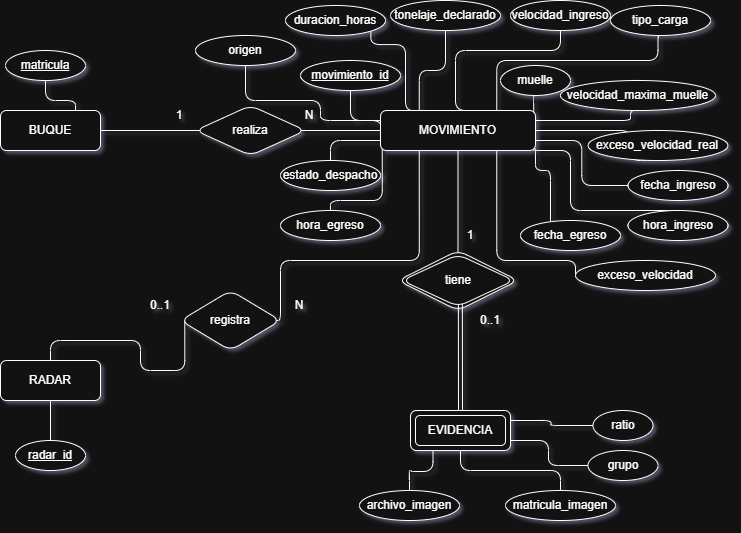

### Modelo lógico (diagrama de tablas)

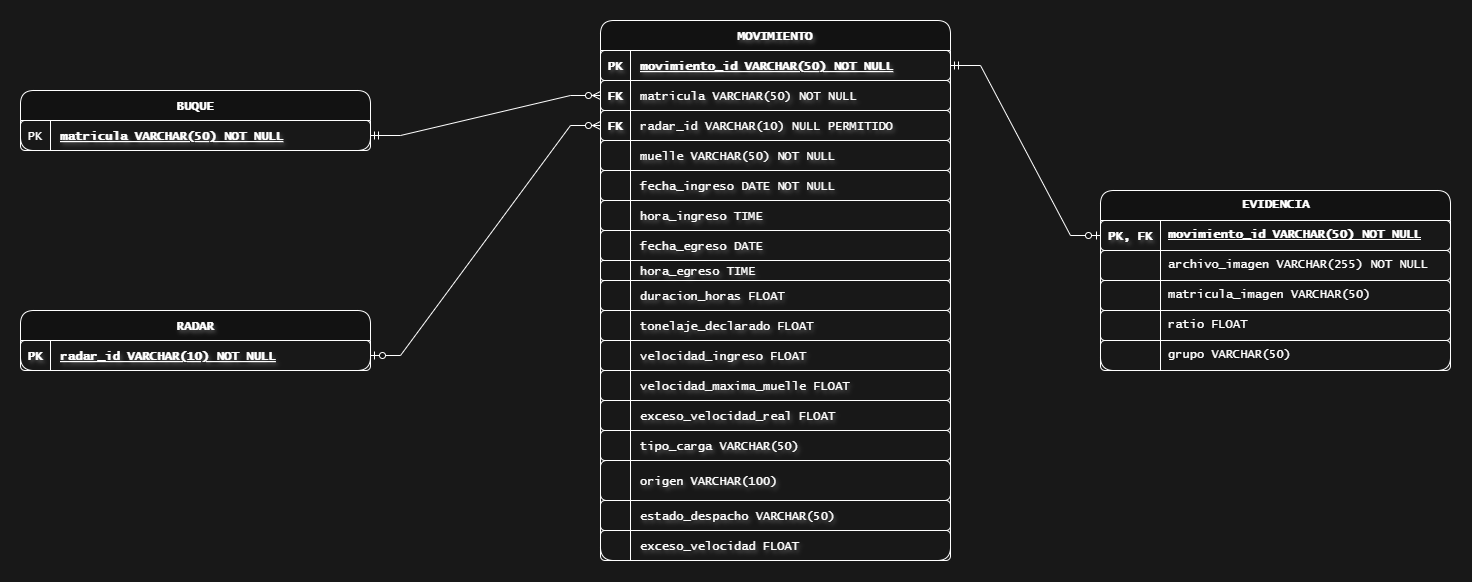

In [ ]:
#@title Registrar Día 3 en git
registrar_dia(
    3,
    "Diseño del modelo lógico",
    [
        "Análisis de `port_movements_image.csv` para justificar el "
        "modelo.",
        "Diseño del modelo lógico de Buque, Movimiento, Radar y "
        "Evidencia con atributos y cardinalidades.",
    ],
)

[GIT] Commit 'Día 3: Diseño del modelo lógico' creado.
[GIT] Push desactivado: el commit queda en local.


## Ejercicio 04

> Puntos: 1

Implementar el **modelo relacional** con SQLAlchemy según el diseño del ejercicio anterior.

Cada modelo debe incluir:
- Clave primaria.
- Claves foráneas y relaciones (`relationship`).
- Método `__repr__` para mejor legibilidad.

Luego completar la función `procesar_fila_csv` que mapea una fila del CSV a instancias de los modelos.

In [ ]:
#@title Modelos Buque, Radar, Movimiento y Evidencia
class Base(DeclarativeBase):
    """Clase base declarativa de los modelos del sistema portuario."""


class Buque(Base):
    """Embarcación registrada en el sistema, identificada por su matrícula."""

    __tablename__ = 'buques'

    matricula: Mapped[str] = mapped_column(String(50), primary_key=True)

    movimientos: Mapped[list['Movimiento']] = relationship(
        back_populates='buque'
    )

    def __repr__(self) -> str:
        return f"<Buque(matricula='{self.matricula}')>"


class Radar(Base):
    """Dispositivo de detección móvil que puede operar en varios muelles."""

    __tablename__ = 'radares'

    radar_id: Mapped[str] = mapped_column(String(10), primary_key=True)

    movimientos: Mapped[list['Movimiento']] = relationship(
        back_populates='radar'
    )

    def __repr__(self) -> str:
        return f"<Radar(radar_id='{self.radar_id}')>"


class Movimiento(Base):
    """Ingreso de un buque a un muelle, registrado por un radar."""

    __tablename__ = 'movimientos'

    movimiento_id: Mapped[str] = mapped_column(String(50), primary_key=True)
    matricula: Mapped[str] = mapped_column(
        ForeignKey('buques.matricula'), nullable=False
    )
    radar_id: Mapped[Optional[str]] = mapped_column(
        ForeignKey('radares.radar_id'), nullable=True
    )
    muelle: Mapped[str] = mapped_column(String(50), nullable=False)
    fecha_ingreso: Mapped[date] = mapped_column(Date, nullable=False)
    hora_ingreso: Mapped[Optional[time]] = mapped_column(Time)
    fecha_egreso: Mapped[Optional[date]] = mapped_column(Date)
    hora_egreso: Mapped[Optional[time]] = mapped_column(Time)
    duracion_horas: Mapped[Optional[float]] = mapped_column(Float)
    tonelaje_declarado: Mapped[Optional[float]] = mapped_column(Float)
    velocidad_ingreso: Mapped[Optional[float]] = mapped_column(Float)
    velocidad_maxima_muelle: Mapped[Optional[float]] = mapped_column(Float)
    exceso_velocidad_real: Mapped[Optional[float]] = mapped_column(Float)
    exceso_velocidad: Mapped[Optional[float]] = mapped_column(Float)
    tipo_carga: Mapped[Optional[str]] = mapped_column(String(50))
    origen: Mapped[Optional[str]] = mapped_column(String(100))
    estado_despacho: Mapped[Optional[str]] = mapped_column(String(50))

    buque: Mapped['Buque'] = relationship(back_populates='movimientos')
    radar: Mapped[Optional['Radar']] = relationship(
        back_populates='movimientos'
    )
    evidencia: Mapped[Optional['Evidencia']] = relationship(
        back_populates='movimiento', cascade='all, delete-orphan'
    )

    def __repr__(self) -> str:
        return (f"<Movimiento(movimiento_id='{self.movimiento_id}', "
                f"matricula='{self.matricula}', "
                f"radar_id='{self.radar_id}', muelle='{self.muelle}', "
                f"fecha_ingreso={self.fecha_ingreso})>")


class Evidencia(Base):
    """Imagen opcional que respalda a un único movimiento."""

    __tablename__ = 'evidencias'

    movimiento_id: Mapped[str] = mapped_column(
        ForeignKey('movimientos.movimiento_id'), primary_key=True
    )
    archivo_imagen: Mapped[str] = mapped_column(String(255), nullable=False)
    matricula_imagen: Mapped[Optional[str]] = mapped_column(String(50))
    ratio: Mapped[Optional[float]] = mapped_column(Float)
    grupo: Mapped[Optional[str]] = mapped_column(String(50))

    movimiento: Mapped['Movimiento'] = relationship(
        back_populates='evidencia'
    )

    def __repr__(self) -> str:
        return (f"<Evidencia(movimiento_id='{self.movimiento_id}', "
                f"archivo_imagen='{self.archivo_imagen}', "
                f"grupo='{self.grupo}', ratio={self.ratio})>")

In [ ]:
#@title Funciones auxiliares de conversión de valores del CSV
def es_vacio(valor: Any) -> bool:
    """Indica si un valor del CSV debe considerarse nulo (None, NaN o '')."""
    if valor is None:
        return True
    if isinstance(valor, float) and math.isnan(valor):
        return True
    return isinstance(valor, str) and valor.strip() == ''


def a_texto(valor: Any) -> Optional[str]:
    """Convierte un valor a texto sin espacios extremos, o None si es nulo."""
    return None if es_vacio(valor) else str(valor).strip()


def a_float(valor: Any) -> Optional[float]:
    """Convierte un valor a float, o None si es nulo o no es numérico."""
    if es_vacio(valor):
        return None
    try:
        return float(valor)
    except (TypeError, ValueError):
        return None


def a_fecha(valor: Any) -> Optional[date]:
    """Convierte 'YYYY-MM-DD' o un datetime a date (None si no es válido)."""
    if es_vacio(valor):
        return None
    if isinstance(valor, datetime):
        return valor.date()
    if isinstance(valor, date):
        return valor
    try:
        return date.fromisoformat(str(valor).strip()[:10])
    except ValueError:
        return None


def a_hora(valor: Any) -> Optional[time]:
    """Convierte 'HH:MM' a time, o None si no es válido."""
    if es_vacio(valor):
        return None
    if isinstance(valor, time):
        return valor
    try:
        return time.fromisoformat(str(valor).strip())
    except ValueError:
        return None


def estandarizar_ratio(valor: Any) -> Optional[float]:
    """Lleva el ratio de coincidencia de escala 0-100 a escala 0-1."""
    ratio = a_float(valor)
    if ratio is not None and ratio > 1:
        ratio = ratio / 100
    return ratio


def estandarizar_grupo(valor: Any) -> Optional[str]:
    """Estandariza el grupo de imagen a singular: 'plates' -> 'plate'."""
    grupo = a_texto(valor)
    return None if grupo is None else grupo.lower().removesuffix('s')

In [ ]:
#@title Función procesar_fila_csv
BUQUES_CACHE: dict[str, Buque] = {}
RADARES_CACHE: dict[str, Radar] = {}


def reiniciar_cache() -> None:
    """Vacía los buques y radares en memoria antes de una nueva migración."""
    BUQUES_CACHE.clear()
    RADARES_CACHE.clear()


def obtener_buque(matricula: str) -> Buque:
    """Devuelve el Buque de la matrícula, creándolo si aún no existe."""
    if matricula not in BUQUES_CACHE:
        BUQUES_CACHE[matricula] = Buque(matricula=matricula)
    return BUQUES_CACHE[matricula]


def obtener_radar(radar_id: str) -> Radar:
    """Devuelve el Radar indicado, creándolo si aún no existe."""
    if radar_id not in RADARES_CACHE:
        RADARES_CACHE[radar_id] = Radar(radar_id=radar_id)
    return RADARES_CACHE[radar_id]


def procesar_fila_csv(row: dict) -> Movimiento:
    """Mapea un diccionario de fila CSV a instancias del modelo.

    Reutiliza el mismo objeto Buque (por matrícula) y Radar (por radar_id)
    entre filas, para que al insertar no se dupliquen registros. Solo crea
    la Evidencia si la fila tiene imagen asociada.

    Args:
        row (dict): Fila del archivo port_movements_image.csv.

    Returns:
        Movimiento: Instancia con relaciones Buque, Radar y Evidencia.

    Raises:
        ValueError: Si la fila no tiene movimiento_id o matrícula.
    """
    movimiento_id = a_texto(row.get('movimiento_id'))
    matricula = a_texto(row.get('matricula'))
    if movimiento_id is None or matricula is None:
        raise ValueError(f'Fila sin movimiento_id o matrícula: {row}')

    radar_id = a_texto(row.get('radar_id'))

    movimiento = Movimiento(
        movimiento_id=movimiento_id,
        muelle=a_texto(row.get('muelle')),
        fecha_ingreso=a_fecha(row.get('fecha_ingreso')),
        hora_ingreso=a_hora(row.get('hora_ingreso')),
        fecha_egreso=a_fecha(row.get('fecha_egreso')),
        hora_egreso=a_hora(row.get('hora_egreso')),
        duracion_horas=a_float(row.get('duracion_horas')),
        tonelaje_declarado=a_float(row.get('tonelaje_declarado')),
        velocidad_ingreso=a_float(row.get('velocidad_ingreso')),
        velocidad_maxima_muelle=a_float(row.get('velocidad_maxima_muelle')),
        exceso_velocidad_real=a_float(row.get('exceso_velocidad_real')),
        exceso_velocidad=a_float(row.get('exceso_velocidad')),
        tipo_carga=a_texto(row.get('tipo_carga')),
        origen=a_texto(row.get('origen')),
        estado_despacho=a_texto(row.get('estado_despacho')),
        buque=obtener_buque(matricula),
        radar=obtener_radar(radar_id) if radar_id else None,
    )

    archivo_imagen = a_texto(row.get('imagen'))
    if archivo_imagen is not None:
        movimiento.evidencia = Evidencia(
            archivo_imagen=archivo_imagen,
            matricula_imagen=a_texto(row.get('matricula_imagen')),
            ratio=estandarizar_ratio(row.get('ratio')),
            grupo=estandarizar_grupo(row.get('grupo_imagen')),
        )

    return movimiento

In [ ]:
#@title Validación
row_ejemplo = {
  'movimiento_id': 'MOV-00042',
  'matricula': 'MSC-GENOVA',
  'fecha_ingreso': '2023-08-14',
  'hora_ingreso': '03:15',
  'fecha_egreso': '2023-08-15',
  'duracion_horas': 20.5,
  'tonelaje_declarado': 4800.5,
  'velocidad_ingreso': 14.2,
  'velocidad_maxima_muelle': 12,
  'exceso_velocidad_real': 2.2,
  'exceso_velocidad': 1.6,
  'muelle': 'MUELLE-B',
  'tipo_carga': 'SOJA',
  'origen': 'ROTTERDAM',
  'radar_id': 'R-03',
  'estado_despacho': 'PENDIENTE',
  'imagen': 'foto_buque_042.jpg',
  'matricula_imagen': 'MSC-GEN0VA',
  'ratio': 0.90,
  'grupo_imagen': 'plate'
}

mov:Movimiento = procesar_fila_csv(row_ejemplo)
print(f"Movimiento: {mov.movimiento_id}")
print(f"Buque: {mov.buque.matricula}")
print(f"Radar: {mov.radar.radar_id} en {mov.muelle}")
print(f"Duración estadía: {mov.duracion_horas}hs")
if mov.evidencia:
  print(f"Evidencia: {mov.evidencia.archivo_imagen} "
        f"(ratio {mov.evidencia.ratio:.0%}, "
        f"grupo: {mov.evidencia.grupo})")

Movimiento: MOV-00042
Buque: MSC-GENOVA
Radar: R-03 en MUELLE-B
Duración estadía: 20.5hs
Evidencia: foto_buque_042.jpg (ratio 90%, grupo: plate)


In [ ]:
#@title Registrar Día 4 en git
registrar_dia(
    4,
    "Modelo relacional con SQLAlchemy",
    [
        "Implementación de los modelos Buque, Radar, Movimiento y "
        "Evidencia con claves, relaciones y `__repr__`.",
        "Implementación de `procesar_fila_csv` para mapear filas del CSV "
        "a instancias de los modelos.",
    ],
)

[GIT] Commit 'Día 4: Modelo relacional con SQLAlchemy' creado.
[GIT] Push desactivado: el commit queda en local.


## Ejercicio 05

> Puntos: 1

Crear y poblar la base de datos `transito_portuario` con los datos de `port_log/data/processed/port_movements_image.csv`.

- Crear la base de datos con SQLAlchemy y generar las tablas automáticamente.
- Migrar los datos desde el CSV usando `procesar_fila_csv`.
- Validar la cantidad de registros insertados en cada tabla:
```
Buques insertados:     XX
Radares insertados:    XX
Movimientos insertados: XX
Evidencias insertadas: XX
```

In [ ]:
#@title Crear la base de datos transito_portuario
RUTA_BASE_DATOS: Path = DIR_DATOS / "transito_portuario.db"
RUTA_BASE_DATOS.parent.mkdir(parents=True, exist_ok=True)

engine: Engine = create_engine(
    URL.create("sqlite", database=str(RUTA_BASE_DATOS.resolve()))
)
SessionLocal: sessionmaker[Session] = sessionmaker(bind=engine)
Base.metadata.create_all(engine)

In [ ]:
#@title Migrar el CSV y validar las cantidades por tabla
def migrar_datos_csv(ruta_csv: Path) -> dict[str, int]:
    """Reemplaza los datos con el CSV en una única transacción.

    Valida los identificadores y los conteos antes de confirmar los cambios.
    Si la carga falla, se conserva el contenido anterior de las tablas.
    """
    if not ruta_csv.is_file():
        raise FileNotFoundError(f"No se encontró el dataset: {ruta_csv}")

    datos = pd.read_csv(ruta_csv, dtype=str, keep_default_na=False)
    columnas_requeridas = {
        "movimiento_id", "matricula", "muelle", "fecha_ingreso", "imagen"
    }
    faltantes = columnas_requeridas.difference(datos.columns)
    if faltantes:
        raise ValueError(f"Faltan columnas: {', '.join(sorted(faltantes))}")

    identificadores = datos["movimiento_id"].str.strip()
    if identificadores.eq("").any() or identificadores.duplicated().any():
        raise ValueError("Los movimiento_id deben ser únicos y no vacíos.")

    reiniciar_cache()
    try:
        movimientos = [
            procesar_fila_csv(fila)
            for fila in datos.to_dict(orient="records")
        ]
        esperados = {
            "buques": len(BUQUES_CACHE),
            "radares": len(RADARES_CACHE),
            "movimientos": len(movimientos),
            "evidencias": sum(
                movimiento.evidencia is not None
                for movimiento in movimientos
            ),
        }
        modelos = {
            "buques": Buque,
            "radares": Radar,
            "movimientos": Movimiento,
            "evidencias": Evidencia,
        }
        with SessionLocal.begin() as sesion:
            for modelo in (Evidencia, Movimiento, Radar, Buque):
                sesion.execute(delete(modelo))
            sesion.add_all(movimientos)
            sesion.flush()
            cantidades = {
                nombre: sesion.scalar(select(func.count()).select_from(modelo))
                or 0
                for nombre, modelo in modelos.items()
            }
            if cantidades != esperados:
                raise ValueError(
                    f"Conteos incorrectos: {cantidades}; "
                    f"se esperaban {esperados}."
                )
        return cantidades
    finally:
        reiniciar_cache()


cantidades_insertadas = migrar_datos_csv(RUTA_PROCESSED_IMG)
print(f"Buques insertados:      {cantidades_insertadas['buques']}")
print(f"Radares insertados:     {cantidades_insertadas['radares']}")
print(f"Movimientos insertados: {cantidades_insertadas['movimientos']}")
print(f"Evidencias insertadas:  {cantidades_insertadas['evidencias']}")

Buques insertados:      20
Radares insertados:     8
Movimientos insertados: 474
Evidencias insertadas:  456


In [ ]:
#@title Registrar Día 5 en git
registrar_dia(
    5,
    "Creación y carga de la base de datos transito_portuario",
    [
        "Creación automática de las tablas con SQLAlchemy y SQLite.",
        "Migración transaccional del CSV usando procesar_fila_csv.",
        "Validación de conteos y carga repetible sin duplicar registros.",
    ],
)

[GIT] Commit 'Día 5: Creación y carga de la base de datos transito_portuario' creado.
[GIT] Push desactivado: el commit queda en local.


## Ejercicio 06

> Puntos: 1

Implementar consultas SQLAlchemy sobre la base de datos:

- Top 10 buques con mayor cantidad de infracciones, ordenado de forma descendente:
```
--- Top 10 buques con más infracciones ---
Matrícula          | Cantidad  
------------------ | ----------
XXXXXXXXXX         | YY
```


### Criterios para las consultas

Se considera infracción un movimiento con `exceso_velocidad_real > 0`.
Los movimientos sin evidencia se buscan sobre todos los movimientos.
La cobertura visual se calcula por la presencia de una imagen asociada.
Para reincidencia se elige el último año calendario con fechas válidas en
el dataset, excluyendo la fecha centinela `1900-01-01`, y se requieren al
menos dos infracciones dentro de ese período.


In [ ]:
#@title Top 10 buques con más infracciones
def mostrar_top_buques() -> None:
    """Muestra los diez buques con más excesos de velocidad reales."""
    cantidad = func.count(Movimiento.movimiento_id).label("cantidad")
    consulta = (
        select(Buque.matricula, cantidad)
        .join(Buque.movimientos)
        .where(Movimiento.exceso_velocidad_real > 0)
        .group_by(Buque.matricula)
        .order_by(cantidad.desc(), Buque.matricula)
        .limit(10)
    )
    with SessionLocal() as sesion:
        print("--- Top 10 buques con más infracciones ---")
        print(f"{'Matrícula':<18} | Cantidad")
        print(f"{'-' * 18} | {'-' * 10}")
        for matricula, total in sesion.execute(consulta):
            print(f"{matricula:<18} | {total}")


mostrar_top_buques()

--- Top 10 buques con más infracciones ---
Matrícula          | Cantidad
------------------ | ----------
COSCO TIGRE        | 32
ONE PARANA         | 32
YANG ESTE          | 29
CMA ROSARIO        | 28
MAERSK LIMA        | 27
COSCO STAR         | 26
EVER GLORY         | 26
MSC GENOVA         | 26
EVERGREEN 02       | 23
PIL SANTA          | 23



- Top 10 movimientos más recientes sin evidencia, ordenado de forma descendente por fecha:
```
--- Total sin evidencia: XXX ---
Movimiento         | Fecha      | Matrícula
------------------ | ---------- | ----------
MOV-XXXXX          | YYYY-MM-DD | XXXXXXXXXX
```


In [ ]:
#@title Top 10 movimientos más recientes sin evidencia
def mostrar_movimientos_sin_evidencia() -> None:
    """Cuenta todos los movimientos sin evidencia y muestra los recientes."""
    sin_evidencia = ~Movimiento.evidencia.has()
    consulta = (
        select(
            Movimiento.movimiento_id,
            Movimiento.fecha_ingreso,
            Movimiento.matricula,
        )
        .where(sin_evidencia)
        .order_by(
            Movimiento.fecha_ingreso.desc(),
            Movimiento.hora_ingreso.desc(),
            Movimiento.movimiento_id.desc(),
        )
        .limit(10)
    )
    with SessionLocal() as sesion:
        total = sesion.scalar(
            select(func.count())
            .select_from(Movimiento)
            .where(sin_evidencia)
        ) or 0
        print(f"--- Total sin evidencia: {total} ---")
        print(f"{'Movimiento':<18} | {'Fecha':<10} | Matrícula")
        print(f"{'-' * 18} | {'-' * 10} | {'-' * 10}")
        for movimiento_id, fecha, matricula in sesion.execute(consulta):
            print(f"{movimiento_id:<18} | {fecha.isoformat()} | {matricula}")


mostrar_movimientos_sin_evidencia()

--- Total sin evidencia: 18 ---
Movimiento         | Fecha      | Matrícula
------------------ | ---------- | ----------
MOV-00027          | 2024-11-06 | ZIM NORTE
MOV-00973          | 2024-08-27 | ZIM NORTE
MOV-00133          | 2024-05-30 | ZIM NORTE
MOV-01353          | 2023-01-11 | ZIM NORTE
MOV-01004          | 2022-12-13 | ZIM NORTE
MOV-00513          | 2022-12-11 | ZIM NORTE
MOV-01238          | 2022-08-08 | ZIM NORTE
MOV-01082          | 2022-08-02 | ZIM NORTE
MOV-01156          | 2022-07-26 | ZIM NORTE
MOV-01379          | 2022-03-07 | ZIM NORTE



- Radares más activos con la cantidad de muelles distintos en los que operaron, ordenados de forma descendente:
```
Radar      | Muelles distintos | Infracciones
---------- | ----------------- | ------------
R-XX       | X                 | ZZ
```


In [ ]:
#@title Radares más activos y muelles distintos
def mostrar_radares_activos() -> None:
    """Ordena radares por infracciones y cuenta todos sus muelles operados."""
    muelles_por_radar = (
        select(
            Movimiento.radar_id,
            func.count(func.distinct(Movimiento.muelle)).label("muelles"),
        )
        .where(Movimiento.radar_id.is_not(None))
        .group_by(Movimiento.radar_id)
        .subquery()
    )
    cantidad = func.count(Movimiento.movimiento_id).label("infracciones")
    consulta = (
        select(Radar.radar_id, muelles_por_radar.c.muelles, cantidad)
        .join(
            muelles_por_radar,
            Radar.radar_id == muelles_por_radar.c.radar_id,
        )
        .outerjoin(
            Movimiento,
            (Radar.radar_id == Movimiento.radar_id)
            & (Movimiento.exceso_velocidad_real > 0),
        )
        .group_by(Radar.radar_id, muelles_por_radar.c.muelles)
        .order_by(cantidad.desc(), Radar.radar_id)
    )
    with SessionLocal() as sesion:
        print(f"{'Radar':<10} | {'Muelles distintos':<17} | Infracciones")
        print(f"{'-' * 10} | {'-' * 17} | {'-' * 12}")
        for radar_id, muelles, infracciones in sesion.execute(consulta):
            print(f"{radar_id:<10} | {muelles:<17} | {infracciones}")


mostrar_radares_activos()

Radar      | Muelles distintos | Infracciones
---------- | ----------------- | ------------
R-07       | 6                 | 71
R-01       | 6                 | 60
R-04       | 6                 | 59
R-05       | 6                 | 58
R-02       | 6                 | 54
R-08       | 6                 | 53
R-03       | 6                 | 49
R-06       | 6                 | 49



- Top 10 reincidentes en un período definido por el alumno, descendente:
```
--- Top 10 reincidentes (YYYY-MM-DD a YYYY-MM-DD) ---
Matrícula          | Cantidad  
------------------ | ----------
```


In [ ]:
#@title Top 10 reincidentes en el último año válido del dataset
def mostrar_reincidentes(fecha_inicio: date, fecha_fin: date) -> None:
    """Muestra buques con al menos dos infracciones dentro del período."""
    if fecha_inicio > fecha_fin:
        raise ValueError("La fecha inicial no puede superar la fecha final.")

    cantidad = func.count(Movimiento.movimiento_id).label("cantidad")
    consulta = (
        select(Buque.matricula, cantidad)
        .join(Buque.movimientos)
        .where(
            Movimiento.exceso_velocidad_real > 0,
            Movimiento.fecha_ingreso.between(fecha_inicio, fecha_fin),
        )
        .group_by(Buque.matricula)
        .having(cantidad >= 2)
        .order_by(cantidad.desc(), Buque.matricula)
        .limit(10)
    )
    with SessionLocal() as sesion:
        print(
            f"--- Top 10 reincidentes ({fecha_inicio.isoformat()} a "
            f"{fecha_fin.isoformat()}) ---"
        )
        print(f"{'Matrícula':<18} | Cantidad")
        print(f"{'-' * 18} | {'-' * 10}")
        for matricula, total in sesion.execute(consulta):
            print(f"{matricula:<18} | {total}")


with SessionLocal() as sesion:
    ultima_fecha = sesion.scalar(
        select(func.max(Movimiento.fecha_ingreso)).where(
            Movimiento.fecha_ingreso > date(1900, 1, 1)
        )
    )

if ultima_fecha is None:
    print("No hay fechas válidas para definir un período de reincidencia.")
else:
    fecha_inicio_reincidencia = date(ultima_fecha.year, 1, 1)
    fecha_fin_reincidencia = date(ultima_fecha.year, 12, 31)
    mostrar_reincidentes(fecha_inicio_reincidencia, fecha_fin_reincidencia)

--- Top 10 reincidentes (2024-01-01 a 2024-12-31) ---
Matrícula          | Cantidad
------------------ | ----------
COSCO STAR         | 11
COSCO TIGRE        | 10
MAERSK PAMPAS      | 9
EVER GLORY         | 8
ONE PARANA         | 7
YANG ESTE          | 7
MSC GENOVA         | 6
CMA ROSARIO        | 5
HAPAG SUR          | 5
MSC ALPHA          | 5



- Promedio de exceso de velocidad por muelle, descendente:
```
--- Exceso promedio por muelle ---
Muelle     | Exceso Prom. (nudos)
---------- | --------------------
MUELLE-X   | XX.XX
```


In [ ]:
#@title Promedio de exceso de velocidad por muelle
def mostrar_exceso_promedio() -> None:
    """Promedia el exceso real de las infracciones de cada muelle."""
    promedio = func.avg(Movimiento.exceso_velocidad_real).label("promedio")
    consulta = (
        select(Movimiento.muelle, promedio)
        .where(Movimiento.exceso_velocidad_real > 0)
        .group_by(Movimiento.muelle)
        .order_by(promedio.desc(), Movimiento.muelle)
    )
    with SessionLocal() as sesion:
        print("--- Exceso promedio por muelle ---")
        print(f"{'Muelle':<10} | Exceso Prom. (nudos)")
        print(f"{'-' * 10} | {'-' * 20}")
        for muelle, exceso_promedio in sesion.execute(consulta):
            print(f"{muelle:<10} | {exceso_promedio:.2f}")


mostrar_exceso_promedio()

--- Exceso promedio por muelle ---
Muelle     | Exceso Prom. (nudos)
---------- | --------------------
MUELLE D   | 3.28
MUELLE A   | 3.13
MUELLE F   | 3.08
MUELLE E   | 3.03
MUELLE C   | 2.88
MUELLE B   | 2.80



- Porcentaje de infracciones confirmadas visualmente:
```
--- Cobertura de evidencia ---
Total infracciones:       XXXX
Con imagen asociada:       XXX
Porcentaje confirmado:  XX.XX%
```

In [ ]:
#@title Porcentaje de infracciones con imagen asociada
def mostrar_cobertura_evidencia() -> None:
    """Calcula la cobertura de imágenes sobre las infracciones reales."""
    infraccion = Movimiento.exceso_velocidad_real > 0
    with SessionLocal() as sesion:
        total = sesion.scalar(
            select(func.count()).select_from(Movimiento).where(infraccion)
        ) or 0
        con_imagen = sesion.scalar(
            select(func.count())
            .select_from(Movimiento)
            .where(infraccion, Movimiento.evidencia.has())
        ) or 0

    porcentaje = 100 * con_imagen / total if total else 0.0
    print("--- Cobertura de evidencia ---")
    print(f"Total infracciones:     {total:>6}")
    print(f"Con imagen asociada:    {con_imagen:>6}")
    print(f"Porcentaje confirmado: {porcentaje:>6.2f}%")


mostrar_cobertura_evidencia()

--- Cobertura de evidencia ---
Total infracciones:        474
Con imagen asociada:       456
Porcentaje confirmado:  96.20%


In [ ]:
#@title Registrar Día 6 en git
registrar_dia(
    6,
    "Consultas SQLAlchemy sobre el tránsito portuario",
    [
        "Consultas de buques infractores, movimientos sin evidencia "
        "y radares.",
        "Reincidencia anual, exceso promedio por muelle y cobertura visual.",
        "Criterios explícitos, orden descendente y manejo de totales vacíos.",
    ],
)

[GIT] Commit 'Día 6: Consultas SQLAlchemy sobre el tránsito portuario' creado.
[GIT] Push desactivado: el commit queda en local.


## Ejercicio 07

> Puntos: 1

Crear la base de datos vectorial `buque_vectorial` con ChromaDB usando el modelo OpenCLIP.

Para el almacenamiento:
- Usar el `id` del **Buque** (de la base relacional) como identificador del documento.
- Generar el embedding a partir de la imagen `complete` del buque (si tiene más de una, usar la de mayor ratio de coincidencia).
- Si un buque no tiene imagen `complete` asociada, no incluirlo en la base vectorial.

Al finalizar mostrar:
```
Buques en base relacional:    XX
Buques en base vectorial:     XX
Cobertura vectorial:       XX.XX%
```

In [ ]:
#@title Inicializar OpenCLIP
def cargar_modelo_openclip(
    nombre_modelo: str,
    pesos_modelo: str,
    dispositivo: str,
) -> tuple[Any, Any]:
    """Carga el modelo OpenCLIP y su transformación de imágenes."""
    modelo, _, preprocesamiento = open_clip.create_model_and_transforms(
        nombre_modelo,
        pretrained=pesos_modelo,
    )
    modelo = modelo.to(dispositivo)
    modelo.eval()
    return modelo, preprocesamiento


modelo_openclip, preprocesamiento_imagen = cargar_modelo_openclip(
    MODELO_OPENCLIP,
    PESOS_OPENCLIP,
    DISPOSITIVO,
)

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

In [ ]:
#@title Crear o recuperar la colección vectorial de ChromaDB
def crear_coleccion_chromadb(
    ruta_base: str,
    nombre_coleccion: str,
) -> Any:
    """Crea un cliente persistente y recupera o crea una colección vectorial.

    Args:
        ruta_base: Directorio donde ChromaDB persiste los datos.
        nombre_coleccion: Nombre de la colección que se utilizará.

    Returns:
        Colección de ChromaDB lista para almacenar y consultar embeddings.
    """
    cliente = chromadb.PersistentClient(path=ruta_base)

    return cliente.get_or_create_collection(
        name=nombre_coleccion,
    )


coleccion_buques = crear_coleccion_chromadb(
    ruta_base=RUTA_BASE_VECTORIAL,
    nombre_coleccion=NOMBRE_BASE_VECTORIAL,
)

print(f"Colección vectorial: {coleccion_buques.name}")
print(f"Documentos almacenados: {coleccion_buques.count()}")

Colección vectorial: buque_vectorial
Documentos almacenados: 0


In [ ]:
#@title Obtener imágenes desde la base relacional y seleccionar las completas
def resolver_ruta_imagen(
    archivo_imagen: str,
) -> Path | None:
    """Localiza una imagen utilizando su ruta original o su nombre de archivo.

    Args:
        archivo_imagen: Ruta absoluta, relativa o nombre de la imagen.

    Returns:
        Ruta absoluta de la imagen si existe; de lo contrario, None.
    """
    ruta_original = Path(str(archivo_imagen))

    candidatos = [
        ruta_original,
        DIRECTORIO_REPO / ruta_original,
        DIR_IMAGENES / ruta_original,
    ]

    for candidato in candidatos:
        if candidato.is_file():
            return candidato.resolve()

    nombre_archivo = ruta_original.name

    if DIR_IMAGENES.is_dir():
        coincidencias = [
            ruta
            for ruta in DIR_IMAGENES.rglob(nombre_archivo)
            if ruta.is_file()
        ]

        if coincidencias:
            return coincidencias[0].resolve()

    return None


def obtener_imagenes_buques(
    session: Any,
) -> pd.DataFrame:
    """Consulta las evidencias de imágenes relacionadas con cada buque.

    Args:
        session: Sesión activa de SQLAlchemy.

    Returns:
        DataFrame con las columnas buque_id, tipo, ratio y ruta_imagen.
        Las imágenes que no se localizan conservan una ruta nula.
    """
    registros = (
        session.query(
            Buque.matricula,
            Evidencia.archivo_imagen,
            Evidencia.ratio,
            Evidencia.grupo,
        )
        .join(
            Movimiento,
            Movimiento.matricula == Buque.matricula,
        )
        .join(
            Evidencia,
            Evidencia.movimiento_id == Movimiento.movimiento_id,
        )
        .all()
    )

    filas: list[dict[str, Any]] = []

    for matricula, archivo_imagen, ratio, grupo in registros:
        ruta = resolver_ruta_imagen(archivo_imagen)

        filas.append({
            "buque_id": matricula,
            "tipo": grupo,
            "ratio": ratio,
            "ruta_imagen": str(ruta) if ruta else None,
        })

    return pd.DataFrame(
        filas,
        columns=[
            "buque_id",
            "tipo",
            "ratio",
            "ruta_imagen",
        ],
    )


with SessionLocal() as sesion:
    df_buques_imagenes = obtener_imagenes_buques(sesion)

print(f"Evidencias consultadas: {len(df_buques_imagenes)}")
print(
    "Imágenes con ruta disponible: "
    f"{df_buques_imagenes['ruta_imagen'].notna().sum()}"
)

display(df_buques_imagenes.head())


def seleccionar_imagenes_complete(
    df_imagenes: pd.DataFrame,
) -> pd.DataFrame:
    """Selecciona una imagen del grupo complete por cada buque.

    Se conservan únicamente los registros con matrícula, ratio numérico
    y ruta de imagen disponible. Si un buque tiene varias imágenes
    complete, se selecciona la que presenta el ratio más alto.

    Args:
        df_imagenes: DataFrame con las evidencias de imágenes.

    Returns:
        DataFrame filtrado con una imagen por matrícula.
    """
    columnas_requeridas = {
        "buque_id",
        "tipo",
        "ratio",
        "ruta_imagen",
    }

    faltantes = columnas_requeridas - set(df_imagenes.columns)

    if faltantes:
        raise ValueError(
            f"Faltan columnas requeridas: {sorted(faltantes)}"
        )

    imagenes = df_imagenes.copy()

    imagenes["ratio"] = pd.to_numeric(
        imagenes["ratio"],
        errors="coerce",
    )

    imagenes = imagenes.dropna(
        subset=["buque_id", "ratio", "ruta_imagen"],
    )

    imagenes = imagenes[
        imagenes["tipo"]
        .astype(str)
        .str.strip()
        .str.lower()
        .eq("complete")
    ]

    imagenes = imagenes.sort_values(
        ["buque_id", "ratio"],
        ascending=[True, False],
        kind="stable",
    )

    return (
        imagenes
        .drop_duplicates("buque_id", keep="first")
        .reset_index(drop=True)
    )


df_imagenes_complete = seleccionar_imagenes_complete(
    df_buques_imagenes,
)

print(f"Imágenes seleccionadas: {len(df_imagenes_complete)}")
print(f"Buques representados: {df_imagenes_complete['buque_id'].nunique()}")

display(df_imagenes_complete.head())

Evidencias consultadas: 456
Imágenes con ruta disponible: 456


,buque_id,tipo,ratio,ruta_imagen
0,ONE PLATA,plate,1.0,/content/Port_Log-Grupo_07/port_log/data/raw/i...
1,ONE PLATA,plate,1.0,/content/Port_Log-Grupo_07/port_log/data/raw/i...
2,MSC GENOVA,plate,1.0,/content/Port_Log-Grupo_07/port_log/data/raw/i...
3,MSC GENOVA,plate,1.0,/content/Port_Log-Grupo_07/port_log/data/raw/i...
4,YANG MING,plate,1.0,/content/Port_Log-Grupo_07/port_log/data/raw/i...


Imágenes seleccionadas: 5
Buques representados: 5


,buque_id,tipo,ratio,ruta_imagen
0,EVER GLORY,complete,1.0,/content/Port_Log-Grupo_07/port_log/data/raw/i...
1,HAPAG SUR,complete,1.0,/content/Port_Log-Grupo_07/port_log/data/raw/i...
2,MSC ALPHA,complete,1.0,/content/Port_Log-Grupo_07/port_log/data/raw/i...
3,PIL OESTE,complete,1.0,/content/Port_Log-Grupo_07/port_log/data/raw/i...
4,ZIM DELTA,complete,1.0,/content/Port_Log-Grupo_07/port_log/data/raw/i...


In [ ]:
#@title Generar embeddings normalizados con OpenCLIP
def generar_embedding_imagen(
    ruta_imagen: str,
    modelo: Any,
    preprocesamiento: Any,
    dispositivo: str,
) -> list[float]:
    """Genera un embedding normalizado a partir de una imagen.

    Args:
        ruta_imagen: Ruta del archivo de imagen.
        modelo: Modelo OpenCLIP cargado previamente.
        preprocesamiento: Transformaciones de entrada del modelo.
        dispositivo: Dispositivo de ejecución, por ejemplo, cpu o cuda.

    Returns:
        Embedding normalizado representado como una lista de floats.

    Raises:
        ValueError: Si el embedding contiene valores no finitos o tiene
            una norma nula.
    """
    with Image.open(ruta_imagen) as imagen:
        tensor_imagen = preprocesamiento(
            imagen.convert("RGB")
        ).unsqueeze(0)

    tensor_imagen = tensor_imagen.to(dispositivo)

    with torch.no_grad():
        embedding = modelo.encode_image(tensor_imagen)
        norma = embedding.norm(dim=-1, keepdim=True)

        if not torch.isfinite(embedding).all() or (norma <= 0).any():
            raise ValueError("El embedding generado no es válido.")

        embedding = embedding / norma

    return embedding.cpu().squeeze(0).tolist()

In [ ]:
#@title Generar y almacenar los embeddings de los buques
def almacenar_buques_vectoriales(
    df_imagenes: pd.DataFrame,
    coleccion: Any,
    modelo: Any,
    preprocesamiento: Any,
    dispositivo: str,
) -> dict[str, int]:
    """Genera y almacena un embedding por buque en ChromaDB.

    Antes de procesar las imágenes, elimina los registros existentes
    de la colección. Por tanto, esta función reconstruye su contenido.

    Args:
        df_imagenes: DataFrame con las evidencias de imágenes.
        coleccion: Colección de ChromaDB de destino.
        modelo: Modelo OpenCLIP cargado.
        preprocesamiento: Transformaciones de entrada del modelo.
        dispositivo: Dispositivo de ejecución del modelo.

    Returns:
        Diccionario con la cantidad almacenada, los errores y el total
        final de registros de la colección.
    """
    imagenes_seleccionadas = seleccionar_imagenes_complete(
        df_imagenes,
    )

    # Limpiar la colección para reconstruir sus registros.
    ids_existentes = coleccion.get(include=[])["ids"]

    if ids_existentes:
        coleccion.delete(ids=ids_existentes)

    almacenados = 0
    errores = 0

    for _, fila in imagenes_seleccionadas.iterrows():
        buque_id = str(fila["buque_id"]).strip()
        ruta_imagen = Path(str(fila["ruta_imagen"]))

        try:
            if not buque_id:
                raise ValueError("La matrícula del buque está vacía.")

            if not ruta_imagen.is_file():
                raise FileNotFoundError(
                    f"No existe la imagen: {ruta_imagen}"
                )

            embedding = generar_embedding_imagen(
                ruta_imagen=str(ruta_imagen),
                modelo=modelo,
                preprocesamiento=preprocesamiento,
                dispositivo=dispositivo,
            )

            coleccion.upsert(
                ids=[buque_id],
                embeddings=[embedding],
                metadatas=[{
                    "ruta_imagen": str(ruta_imagen),
                    "ratio": float(fila["ratio"]),
                }],
            )

            almacenados += 1

        except Exception as error:
            print(f"Error al procesar el buque {buque_id}: {error}")
            errores += 1

    return {
        "almacenados": almacenados,
        "errores": errores,
        "total_coleccion": coleccion.count(),
    }

In [ ]:
#@title Ejecutar el almacenamiento vectorial y evaluar su cobertura
resultado_ejercicio_07 = almacenar_buques_vectoriales(
    df_imagenes=df_buques_imagenes,
    coleccion=coleccion_buques,
    modelo=modelo_openclip,
    preprocesamiento=preprocesamiento_imagen,
    dispositivo=DISPOSITIVO,
)

with SessionLocal() as sesion:
    total_buques_relacionales = sesion.scalar(
        select(func.count()).select_from(Buque)
    ) or 0
total_buques_vectoriales = coleccion_buques.count()

cobertura_vectorial = (
    100 * total_buques_vectoriales / total_buques_relacionales
    if total_buques_relacionales
    else 0.0
)

print(f"Buques en la base relacional: {total_buques_relacionales}")
print(f"Buques en la base vectorial:  {total_buques_vectoriales}")
print(f"Cobertura vectorial:          {cobertura_vectorial:.2f}%")
print(f"Embeddings almacenados:       {resultado_ejercicio_07['almacenados']}")
print(f"Errores de procesamiento:     {resultado_ejercicio_07['errores']}")

Buques en la base relacional: 20
Buques en la base vectorial:  5
Cobertura vectorial:          25.00%
Embeddings almacenados:       5
Errores de procesamiento:     0


In [ ]:
#@title Registrar Día 7 en git
registrar_dia(
    7,
    "Generación de embeddings y almacenamiento vectorial de buques",
    [
        "Creación y recuperación de una colección persistente en ChromaDB.",
        "Consulta de evidencias desde SQLAlchemy y resolución de rutas "
        "de imágenes del repositorio.",
        "Filtrado de imágenes del grupo complete y selección de la imagen "
        "con mayor ratio por matrícula.",
        "Generación de embeddings normalizados mediante OpenCLIP.",
        "Almacenamiento de embeddings y metadatos en ChromaDB utilizando "
        "la matrícula del buque como identificador.",
        "Cálculo de cobertura vectorial respecto de la base relacional "
        "y registro de errores de procesamiento.",
    ],
)

[GIT] Commit 'Día 7: Generación de embeddings y almacenamiento vectorial de buques' creado.
[GIT] Push desactivado: el commit queda en local.


## Ejercicio 08

> Puntos: 2

Implementar la función `buscar_buque_por_imagen` que:
1. Recibe la ruta a una imagen.
2. Genera su embedding con OpenCLIP.
3. Consulta la base vectorial para obtener el `buque_id` más similar.
4. Recupera todos los datos del buque desde la base relacional (incluyendo sus movimientos y evidencias).
5. Retorna un diccionario con la información completa.

In [ ]:
#@title Buscar un buque por similitud visual y recuperar sus datos
def buscar_buque_por_imagen(ruta_imagen: str) -> dict[str, Any]:
    """Busca el vecino visual más cercano y devuelve sus datos relacionales.

    Requiere los modelos y SessionLocal de los ejercicios 4 y 5, y el
    modelo OpenCLIP y la colección poblada del ejercicio 7. El id de
    ChromaDB corresponde a Buque.matricula, la PK del modelo del grupo.
    La distancia es una medida de cercanía, no una probabilidad de acierto.
    """
    ruta = resolver_ruta_imagen(ruta_imagen)
    if ruta is None:
        raise FileNotFoundError(f"No se encontró la imagen: {ruta_imagen}")
    if coleccion_buques.count() == 0:
        raise ValueError("La colección está vacía. Ejecutar el ejercicio 7.")

    embedding = generar_embedding_imagen(
        str(ruta), modelo_openclip, preprocesamiento_imagen, DISPOSITIVO,
    )
    resultado = coleccion_buques.query(
        query_embeddings=[embedding],
        n_results=1,
        include=["distances", "metadatas"],
    )
    if not resultado.get("ids") or not resultado["ids"][0]:
        raise ValueError("La búsqueda vectorial no devolvió buques.")

    matricula = resultado["ids"][0][0]

    def a_diccionario(instancia: Any) -> dict[str, Any]:
        """Serializa todas las columnas; fechas y horas usan formato ISO."""
        datos = {}
        for columna in instancia.__table__.columns:
            valor = getattr(instancia, columna.key)
            if isinstance(valor, (date, datetime, time)):
                valor = valor.isoformat()
            datos[columna.key] = valor
        return datos

    with SessionLocal() as sesion_busqueda:
        buque = sesion_busqueda.get(Buque, matricula)
        if buque is None:
            raise ValueError(
                f"El buque {matricula} de ChromaDB no existe en la base "
                "relacional. Reconstruir la colección con el ejercicio 7."
            )
        datos_buque = a_diccionario(buque)
        datos_buque["movimientos"] = []
        for movimiento in sorted(
            buque.movimientos, key=lambda item: item.movimiento_id,
        ):
            datos_movimiento = a_diccionario(movimiento)
            datos_movimiento["evidencia"] = (
                a_diccionario(movimiento.evidencia)
                if movimiento.evidencia is not None else None
            )
            datos_buque["movimientos"].append(datos_movimiento)

    return {
        "buque_id": matricula,
        "imagen_consulta": str(ruta),
        "distancia": float(resultado["distances"][0][0]),
        "buque": datos_buque,
        "advertencia": (
            "El resultado es el buque indexado más parecido, no una "
            "identificación confirmada. La colección contiene imágenes "
            "complete: una plate muestra solo la matrícula y puede producir "
            "una coincidencia incorrecta. OpenCLIP compara rasgos visuales; "
            "esta búsqueda no realiza OCR."
        ),
    }

In [ ]:
#@title Validación: resultados de búsqueda en formato legible
def mostrar_resultado_busqueda(
    resultado: dict[str, Any], titulo: str,
) -> None:
    """Presenta el resultado sin imprimir el diccionario completo."""
    movimientos = resultado["buque"]["movimientos"]
    cantidad_evidencias = sum(
        movimiento["evidencia"] is not None
        for movimiento in movimientos
    )

    display(Markdown(f"### {titulo}"))
    display(pd.DataFrame([{
        "Buque encontrado": resultado["buque_id"],
        "Imagen consultada": Path(resultado["imagen_consulta"]).name,
        "Distancia vectorial": round(resultado["distancia"], 6),
        "Movimientos": len(movimientos),
        "Evidencias": cantidad_evidencias,
    }]))

    display(Markdown(
        "**Interpretación:** menor distancia indica mayor cercanía visual. "
        "La distancia no representa un porcentaje de confianza."
    ))

    if not movimientos:
        display(Markdown("Este buque no tiene movimientos registrados."))
    else:
        datos_movimientos = []
        datos_evidencias = []

        for movimiento in movimientos:
            fila = {
                clave: valor
                for clave, valor in movimiento.items()
                if clave != "evidencia"
            }
            fila["tiene_evidencia"] = movimiento["evidencia"] is not None
            datos_movimientos.append(fila)

            if movimiento["evidencia"] is not None:
                datos_evidencias.append(movimiento["evidencia"])

        with pd.option_context(
            "display.max_columns", None,
            "display.max_rows", 20,
            "display.max_colwidth", 45,
        ):
            display(Markdown("**Movimientos del buque**"))
            display(pd.DataFrame(datos_movimientos))

            display(Markdown("**Evidencias asociadas**"))
            if datos_evidencias:
                display(pd.DataFrame(datos_evidencias))
            else:
                display(Markdown("No hay evidencias asociadas."))

    display(Markdown(f"**Advertencia:** {resultado['advertencia']}"))


result = buscar_buque_por_imagen(
    "port_log/data/raw/imgs/completes/0001_complete_patente.jpg"
)
mostrar_resultado_busqueda(result, "Prueba con imagen complete")

result2 = buscar_buque_por_imagen(
    "port_log/data/raw/imgs/plates/0001_plate_patente.jpg"
)
mostrar_resultado_busqueda(result2, "Prueba con imagen plate")

### Prueba con imagen complete

,Buque encontrado,Imagen consultada,Distancia vectorial,Movimientos,Evidencias
0,MSC ALPHA,0001_complete_patente.jpg,1.051937,20,20


**Interpretación:** menor distancia indica mayor cercanía visual. La distancia no representa un porcentaje de confianza.

**Movimientos del buque**

,movimiento_id,matricula,radar_id,muelle,fecha_ingreso,hora_ingreso,fecha_egreso,hora_egreso,duracion_horas,tonelaje_declarado,velocidad_ingreso,velocidad_maxima_muelle,exceso_velocidad_real,exceso_velocidad,tipo_carga,origen,estado_despacho,tiene_evidencia
0,MOV-00045,MSC ALPHA,R-08,MUELLE E,2024-01-02,02:32:00,2024-01-03,16:59:00,38.45,7045.67,15.9,12.0,3.9,3.30,MAIZ,SANTA FE,RECHAZADO,True
1,MOV-00053,MSC ALPHA,R-02,MUELLE A,2023-11-13,14:22:00,2023-11-16,06:21:00,63.98,3200.68,13.6,10.0,3.6,3.10,ACEITE,VALPARAISO,EN REVISION,True
2,MOV-00204,MSC ALPHA,R-06,MUELLE C,2022-10-23,16:53:00,2022-10-24,19:46:00,26.88,6017.96,13.1,12.0,1.1,0.50,CONTENEDORES,VALPARAISO,DESPACHADO,True
3,MOV-00220,MSC ALPHA,R-01,MUELLE A,2024-04-16,20:21:00,2024-04-19,00:00:00,51.65,NaN,16.0,10.0,6.0,5.50,GRANOS,MONTEVIDEO,EN REVISION,True
4,MOV-00293,MSC ALPHA,R-06,MUELLE E,2024-10-19,06:08:00,2024-10-20,01:21:00,19.22,5062.71,13.9,12.0,1.9,1.30,TRIGO,BUENOS AIRES,DESPACHADO,True
5,MOV-00399,MSC ALPHA,R-02,MUELLE D,2024-05-31,14:44:00,2024-06-02,04:18:00,37.57,3993.35,15.8,12.0,3.8,3.20,MINERALES,SAO PAULO,EN REVISION,True
6,MOV-00586,MSC ALPHA,R-02,MUELLE A,2020-01-08,00:00:00,2020-01-10,00:00:00,48.00,NaN,13.3,10.0,3.3,2.80,GRANOS,SAO PAULO,DESPACHADO,True
7,MOV-00677,MSC ALPHA,R-05,MUELLE F,2022-08-28,00:29:00,2022-08-29,18:04:00,41.58,5556.49,13.2,10.0,3.2,2.70,CONTENEDORES,BUENOS AIRES,RECHAZADO,True
8,MOV-00770,MSC ALPHA,R-05,MUELLE D,2021-03-26,20:30:00,2021-03-27,03:33:00,7.05,5120.67,15.3,10.0,5.3,4.80,GRANOS,ROTTERDAM,PENDIENTE,True
9,MOV-00915,MSC ALPHA,R-07,MUELLE C,1900-01-01,10:45:00,2020-03-17,05:08:00,NaN,6279.19,14.6,12.0,2.6,2.00,CONTENEDORES,HAMBURG,EN REVISION,True


...

**Movimientos del buque**

,movimiento_id,matricula,radar_id,muelle,fecha_ingreso,hora_ingreso,fecha_egreso,hora_egreso,duracion_horas,tonelaje_declarado,velocidad_ingreso,velocidad_maxima_muelle,exceso_velocidad_real,exceso_velocidad,tipo_carga,origen,estado_despacho,tiene_evidencia
0,MOV-00045,MSC ALPHA,R-08,MUELLE E,2024-01-02,02:32:00,2024-01-03,16:59:00,38.45,7045.67,15.9,12.0,3.9,3.30,MAIZ,SANTA FE,RECHAZADO,True
1,MOV-00053,MSC ALPHA,R-02,MUELLE A,2023-11-13,14:22:00,2023-11-16,06:21:00,63.98,3200.68,13.6,10.0,3.6,3.10,ACEITE,VALPARAISO,EN REVISION,True
2,MOV-00204,MSC ALPHA,R-06,MUELLE C,2022-10-23,16:53:00,2022-10-24,19:46:00,26.88,6017.96,13.1,12.0,1.1,0.50,CONTENEDORES,VALPARAISO,DESPACHADO,True
3,MOV-00220,MSC ALPHA,R-01,MUELLE A,2024-04-16,20:21:00,2024-04-19,00:00:00,51.65,NaN,16.0,10.0,6.0,5.50,GRANOS,MONTEVIDEO,EN REVISION,True
4,MOV-00293,MSC ALPHA,R-06,MUELLE E,2024-10-19,06:08:00,2024-10-20,01:21:00,19.22,5062.71,13.9,12.0,1.9,1.30,TRIGO,BUENOS AIRES,DESPACHADO,True
5,MOV-00399,MSC ALPHA,R-02,MUELLE D,2024-05-31,14:44:00,2024-06-02,04:18:00,37.57,3993.35,15.8,12.0,3.8,3.20,MINERALES,SAO PAULO,EN REVISION,True
6,MOV-00586,MSC ALPHA,R-02,MUELLE A,2020-01-08,00:00:00,2020-01-10,00:00:00,48.00,NaN,13.3,10.0,3.3,2.80,GRANOS,SAO PAULO,DESPACHADO,True
7,MOV-00677,MSC ALPHA,R-05,MUELLE F,2022-08-28,00:29:00,2022-08-29,18:04:00,41.58,5556.49,13.2,10.0,3.2,2.70,CONTENEDORES,BUENOS AIRES,RECHAZADO,True
8,MOV-00770,MSC ALPHA,R-05,MUELLE D,2021-03-26,20:30:00,2021-03-27,03:33:00,7.05,5120.67,15.3,10.0,5.3,4.80,GRANOS,ROTTERDAM,PENDIENTE,True
9,MOV-00915,MSC ALPHA,R-07,MUELLE C,1900-01-01,10:45:00,2020-03-17,05:08:00,NaN,6279.19,14.6,12.0,2.6,2.00,CONTENEDORES,HAMBURG,EN REVISION,True


**Evidencias asociadas**

,movimiento_id,archivo_imagen,matricula_imagen,ratio,grupo
0,MOV-00045,/content/Port_Log-Grupo_07/port_log/data/...,MSC-ALPHA,1.0,complete
1,MOV-00053,/content/Port_Log-Grupo_07/port_log/data/...,MSC-ALPHA,1.0,complete
2,MOV-00204,/content/Port_Log-Grupo_07/port_log/data/...,MSC-ALPHA,1.0,complete
3,MOV-00220,/content/Port_Log-Grupo_07/port_log/data/...,MSC-ALPHA,1.0,complete
4,MOV-00293,/content/Port_Log-Grupo_07/port_log/data/...,MSC-ALPHA,1.0,complete
5,MOV-00399,/content/Port_Log-Grupo_07/port_log/data/...,MSC-ALPHA,1.0,complete
6,MOV-00586,/content/Port_Log-Grupo_07/port_log/data/...,MSC-ALPHA,1.0,complete
7,MOV-00677,/content/Port_Log-Grupo_07/port_log/data/...,MSC-ALPHA,1.0,complete
8,MOV-00770,/content/Port_Log-Grupo_07/port_log/data/...,MSC-ALPHA,1.0,complete
9,MOV-00915,/content/Port_Log-Grupo_07/port_log/data/...,MSC-ALPHA,1.0,complete


**Advertencia:** El resultado es el buque indexado más parecido, no una identificación confirmada. La colección contiene imágenes complete: una plate muestra solo la matrícula y puede producir una coincidencia incorrecta. OpenCLIP compara rasgos visuales; esta búsqueda no realiza OCR.

### Interpretación de la búsqueda

El ejercicio 8 reutiliza el modelo, el preprocesamiento y los embeddings normalizados del ejercicio 7. El identificador recuperado corresponde a la matrícula de la base relacional. Se devuelven todas las columnas del buque, sus movimientos y la evidencia opcional de cada movimiento; fechas y horas se convierten a texto ISO.

La validación anterior compara una imagen completa y un recorte de matrícula. La base vectorial se construyó exclusivamente con imágenes completas, por lo que una `plate` puede recuperar un buque incorrecto. Incluso una imagen `complete` devuelve el vecino más cercano sin garantizar identidad: no se definió un umbral de rechazo y la distancia no es un porcentaje de confianza.



In [ ]:
#@title Registrar Día 8 en git
registrar_dia(
    8,
    "Búsqueda de buques por similitud de imagen",
    [
        "Implementación de `buscar_buque_por_imagen` para recibir la ruta "
        "de una imagen y validar su existencia.",
        "Generación del embedding de la imagen de consulta mediante OpenCLIP.",
        "Consulta de ChromaDB para recuperar el buque visualmente más "
        "similar.",
        "Recuperación de los datos del buque desde SQLAlchemy utilizando "
        "la matrícula obtenida de la búsqueda vectorial.",
        "Obtención de los movimientos asociados al buque y sus evidencias.",
        "Retorno de un diccionario con la matrícula, la distancia vectorial, "
        "los datos de la imagen de referencia, los movimientos y las "
        "evidencias.",
        "Incorporación de validaciones para imágenes inexistentes, colección "
        "vectorial vacía y buques ausentes en la base relacional.",
        "Prueba de la búsqueda con imágenes completas y consideración de las "
        "limitaciones al consultar recortes de matrículas.",
    ],
)

[GIT] Commit 'Día 8: Búsqueda de buques por similitud de imagen' creado.
[GIT] Push desactivado: el commit queda en local.


## Ejercicio 09

> Puntos: 1

Redactar una conclusión integradora del trabajo completo (3 sprints). Debe incluir:

- ¿Qué problema resuelve el sistema desarrollado de extremo a extremo?
- ¿Qué ventaja concreta aporta la base vectorial frente a solo usar OCR para identificar buques?
- ¿Cuáles son las principales limitaciones del sistema actual?
- Si tuvieras que poner este sistema en producción real en el Puerto de Rosario, ¿qué cambiarías y por qué?

## Conclusión integradora

El sistema desarrollado resuelve un problema concreto del puerto: los movimientos registrados por los radares llegaban en archivos CSV cargados en parte a mano, con errores, sin trazabilidad y sin una forma confiable de identificar al buque cuando la matrícula no se podía leer. A lo largo de los tres sprints se construyó una solución de extremo a extremo que va desde la depuración de esos datos hasta la identificación visual de las embarcaciones.

En el **Sprint 1** se depuró el dataset heredado. De 1500 registros se descartaron 255 (17%) por nulos en columnas críticas y valores atípicos, y se excluyeron 772 que no constituían infracción, quedando 474 infracciones. Sobre ellas se identificaron patrones por turno, muelle y tipo de carga, y se mostró que migrar los datos sin limpieza llevaría al sistema velocidades imposibles, estadías inválidas y un mismo buque repartido en varias matrículas. En el **Sprint 2** se incorporó el OCR para vincular las infracciones con imágenes: 456 de ellas (96,20%) quedaron asociadas por matrícula, y los recortes de matrícula (`plates`, 95% de coincidencias) resultaron más útiles que las imágenes completas (`completes`, 90%). Las 7 imágenes sin coincidencia se explicaron por la distancia, la baja iluminación, el desenfoque y la confusión entre caracteres similares.

En el **Sprint 3** ese resultado se profesionalizó. Los archivos binarios y el dataset procesado se versionaron con DVC sobre Supabase, de modo que cada análisis quede asociado a una versión exacta de los datos. Mediante SQLAlchemy se implementó la base de datos `transito_portuario`, con las entidades Buque, Radar, Movimiento y Evidencia, relacionadas para mantener organizada la información. Sobre esta estructura se desarrollaron consultas para identificar los buques con mayor cantidad de infracciones, detectar movimientos sin evidencia, analizar la actividad de los radares, reconocer embarcaciones reincidentes, calcular el exceso de velocidad promedio por muelle y evaluar la cobertura de evidencias visuales. Finalmente, se incorporó ChromaDB como base vectorial y OpenCLIP como modelo de generación de embeddings, permitiendo buscar un buque a partir de una imagen y recuperar sus datos, movimientos y evidencias asociadas desde la base relacional.

La principal ventaja de utilizar una base vectorial frente a depender exclusivamente del OCR es que permite recuperar candidatos mediante la similitud visual entre imágenes, sin necesitar que el sistema lea correctamente los caracteres de una matrícula. Mientras que el OCR se centra en reconocer texto, OpenCLIP transforma las imágenes en representaciones numéricas o *embeddings* que pueden compararse para encontrar imágenes visualmente similares. Esto ofrece una alternativa justamente en los casos en que el OCR falló en el Sprint 2, cuando la matrícula no resulta legible, aunque la similitud visual no garantiza por sí sola que se haya identificado el buque correcto. En nuestra implementación, ChromaDB almacena los embeddings de las imágenes completas de los buques y utiliza la matrícula como identificador. La función de búsqueda genera el embedding de la imagen consultada, recupera el vecino visual más cercano y utiliza su matrícula para obtener la información relacionada desde SQLAlchemy.

Entre las principales limitaciones del sistema actual se encuentra la dependencia de la disponibilidad de imágenes completas para construir la base vectorial. Los buques sin una imagen de este tipo quedan excluidos de las búsquedas visuales, por lo que la cobertura vectorial puede ser inferior a la cobertura de la base relacional. Además, la búsqueda devuelve el vecino más cercano sin aplicar un umbral de rechazo que permita descartar coincidencias poco confiables. La distancia vectorial indica cercanía entre representaciones, pero no constituye una probabilidad de identificación correcta. Asimismo, como la colección se construyó con imágenes completas, consultar únicamente un recorte de matrícula puede producir resultados incorrectos. Por otra parte, los movimientos que no cuentan con evidencia fotográfica no pueden verificarse visualmente mediante este mecanismo. En consecuencia, el sistema permite analizar información y recuperar candidatos, pero no garantiza la identificación inequívoca de todos los buques ni confirma automáticamente la existencia de infracciones.

Para llevar esta solución a producción en el Puerto de Rosario, sería necesario reforzar su confiabilidad, seguridad y capacidad de mantenimiento. En primer lugar, combinaría OCR y similitud visual, aprovechando la lectura de matrículas cuando sea posible y utilizando OpenCLIP como mecanismo complementario de recuperación de candidatos. Incorporaría umbrales de similitud calibrados mediante pruebas con imágenes reales y un procedimiento de revisión humana para los casos dudosos, evitando asignar identidades automáticamente cuando la evidencia sea insuficiente. También ampliaría el conjunto de imágenes de referencia para incluir diferentes ángulos, distancias y condiciones de iluminación, y mediría el rendimiento mediante métricas como la precisión, la tasa de falsos positivos y la tasa de identificaciones correctas. Finalmente, implementaría controles de acceso, auditoría, copias de seguridad, monitoreo, manejo de errores y mecanismos de sincronización entre la base relacional y la vectorial. Estas mejoras permitirían transformar el prototipo académico en una herramienta más robusta para asistir al personal portuario en el seguimiento de movimientos, el análisis de infracciones y la consulta de evidencias, manteniendo la validación humana cuando sea necesaria.

In [ ]:
#@title Registrar Ejercicio 09 en git
registrar_dia(
    9,
    "Conclusión integradora de los tres sprints",
    [
        "Redacción de una conclusión integradora sobre el sistema "
        "desarrollado "
        "a lo largo de los tres sprints.",
        "Descripción del problema de gestión y análisis del tránsito "
        "portuario "
        "que resuelve la solución de extremo a extremo.",
        "Explicación de la ventaja de la búsqueda vectorial con OpenCLIP y "
        "ChromaDB frente al uso exclusivo de OCR.",
        "Identificación de las principales limitaciones del sistema actual, "
        "incluyendo la cobertura de imágenes y la confiabilidad de las "
        "coincidencias.",
        "Propuesta de mejoras para un despliegue en producción en el "
        "Puerto de Rosario, "
        "considerando OCR, validación humana, seguridad, monitoreo y "
        "mantenimiento.",
    ],
)

[GIT] Commit 'Día 9: Conclusión integradora de los tres sprints' creado.
[GIT] Push desactivado: el commit queda en local.
